Data Exploration and Preprocessing

In [1]:
print("Hello Machine Learning world")

Hello Machine Learning world


#Data

## Data folder

In this step we retrieve the data from the folder where it is located

In [2]:
# Connect Google Colab to Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

path = '/content/drive/MyDrive/ML_proj/Projeto/'

Mounted at /content/drive


## Libraries

Here, we install and import the libraries required for the analysis

### Install

In [3]:
# Step 1 - Install pandas using the pip install command
#!pip install pandas
#!pip install numpy
#!pip install matplotlib
#!pip install seaborn

### Import

In [4]:
# Step 2 - Import relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler

#Use the command '%matplotlib inline' after importing matplotlib to guarantee that the plots are on the notebook


#set seaborn as default style for visualizations
sns.set()

## File access

Read the excel file provided

In [5]:
world_citizens = pd.read_excel(path + 'Data/world_citizens.xlsx')

#as a good practice, we avoided working on the dataset imported and created a copy instead
wd_ct = world_citizens.copy()
wd_ct.head(5)

,avg_monthly_entertainment_expenses,avg_weekly_exercise_hours,citizen_id,city,country,date_of_birth,eco_consciousness_score,education_level,environmental_awareness_rating,financial_wellness_index,...,investment_portfolio_value,investments_risk_appetite,investments_risk_tolerance,last_year_charity_donations,marital_status,name,social_media_influence_score,stress_management_score,title,well_being_level
0,8.8730,0.0000,1,Palmas,Brazil,1982-02-15,0.0000,5.5454,0.5576,264.3460,...,0.1313,6.7866,22.9550,0.0000,,Mafalda,2.6469,3.0448,Ms.,3.9098
1,10.9348,0.1298,2,Taupo,New Zealand,1989-11-07,0.0000,4.9150,0.5998,209.9720,...,0.0000,7.2836,17.0296,0.0000,,Olive,2.1466,1.8311,Mrs.,4.4571
2,29.9206,0.1129,3,Nauen,Germany,1972-03-13,0.0000,9.4307,0.6302,21.6053,...,5.1244,4.1800,3.9274,0.0000,,Esther,10.2169,3.9353,Ms.,4.3552
3,36.0014,0.0419,4,Kusel,Germany,1982-04-28,0.0134,8.5129,0.6066,87.0453,...,6.1273,7.1364,6.0943,0.1132,,Ramon,4.9333,NaN,Mr.,5.7737
4,6.0075,1.2697,5,Rize,Turkey,1996-09-05,0.0000,6.0902,1.1385,95.4032,...,6.2140,4.3797,3.1951,0.0000,,Koray,8.2687,2.2987,Mr.,2.5274


#Useful functions used

In [6]:
#Counting outliers
def find_outliers(df):

   q1=df.quantile(0.25)

   q3=df.quantile(0.75)

   IQR=q3-q1

   outliers = df[((df<(q1-1.5*IQR)) | (df>(q3+1.5*IQR)))]

   return outliers

#Copy od the data set without any alterations
wd_ct_original = world_citizens.copy()

#File first look

###What is the data set like?

#### General info

##### Rows and Columns

In [7]:
wd_ct.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8327 entries, 0 to 8326
Data columns (total 22 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   avg_monthly_entertainment_expenses  8077 non-null   float64       
 1   avg_weekly_exercise_hours           8119 non-null   float64       
 2   citizen_id                          8327 non-null   int64         
 3   city                                8327 non-null   object        
 4   country                             8327 non-null   object        
 5   date_of_birth                       8327 non-null   datetime64[ns]
 6   eco_consciousness_score             8119 non-null   float64       
 7   education_level                     8036 non-null   float64       
 8   environmental_awareness_rating      8294 non-null   float64       
 9   financial_wellness_index            8078 non-null   float64       
 10  hapiness_level          

In [8]:
print('(Number of Rows, Number of Columns)')
wd_ct.shape

(Number of Rows, Number of Columns)


(8327, 22)

In [9]:
#wd_ct.columns
i = 1
for col in wd_ct.columns:
  print(f'{i}:\t{col}')
  i += 1

1:	avg_monthly_entertainment_expenses
2:	avg_weekly_exercise_hours
3:	citizen_id
4:	city
5:	country
6:	date_of_birth
7:	eco_consciousness_score
8:	education_level
9:	environmental_awareness_rating
10:	financial_wellness_index
11:	hapiness_level
12:	health_consciousness_rating
13:	investment_portfolio_value
14:	investments_risk_appetite
15:	investments_risk_tolerance
16:	last_year_charity_donations
17:	marital_status
18:	name
19:	social_media_influence_score
20:	stress_management_score
21:	title
22:	well_being_level


##### Statistical information

In [10]:
wd_ct.describe(include = 'all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
avg_monthly_entertainment_expenses,8077.0,NaN,NaN,NaN,21.59006,0.0,8.1283,11.9831,38.7573,135.42,17.409831
avg_weekly_exercise_hours,8119.0,NaN,NaN,NaN,0.707644,-5.5794,0.0224,0.1093,1.02375,8.7017,1.186189
citizen_id,8327.0,NaN,NaN,NaN,4164.0,1.0,2082.5,4164.0,6245.5,8327.0,2403.942179
city,8327,3733,Tauranga,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,8327,22,Spain,446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_of_birth,8327,NaN,NaN,NaN,1988-07-11 03:27:10.311036416,1910-01-04 00:00:00,1981-02-11 00:00:00,1990-01-21 00:00:00,1997-09-06 00:00:00,2024-12-07 00:00:00,NaN
eco_consciousness_score,8119.0,NaN,NaN,NaN,0.131725,-1.4167,0.0,0.0078,0.02445,3.2475,0.358699
education_level,8036.0,NaN,NaN,NaN,6.282893,0.0,4.031225,6.34465,8.559725,14.244,2.918705
environmental_awareness_rating,8294.0,NaN,NaN,NaN,0.827204,0.0376,0.540925,0.6312,0.774475,7.4025,0.65063
financial_wellness_index,8078.0,NaN,NaN,NaN,106.489905,-0.05,87.50485,99.82805,114.0485,458.451,64.306568


In [11]:
#Removing the IDs since the only information we could collect from it its the count which is 8327
quant_descr = wd_ct.drop(['citizen_id'], axis = 1)
quant_descr.describe().T

,count,mean,min,25%,50%,75%,max,std
avg_monthly_entertainment_expenses,8077.0,21.59006,0.0,8.1283,11.9831,38.7573,135.42,17.409831
avg_weekly_exercise_hours,8119.0,0.707644,-5.5794,0.0224,0.1093,1.02375,8.7017,1.186189
date_of_birth,8327,1988-07-11 03:27:10.311036416,1910-01-04 00:00:00,1981-02-11 00:00:00,1990-01-21 00:00:00,1997-09-06 00:00:00,2024-12-07 00:00:00,NaN
eco_consciousness_score,8119.0,0.131725,-1.4167,0.0,0.0078,0.02445,3.2475,0.358699
education_level,8036.0,6.282893,0.0,4.031225,6.34465,8.559725,14.244,2.918705
environmental_awareness_rating,8294.0,0.827204,0.0376,0.540925,0.6312,0.774475,7.4025,0.65063
financial_wellness_index,8078.0,106.489905,-0.05,87.50485,99.82805,114.0485,458.451,64.306568
health_consciousness_rating,8077.0,1.45305,0.0,0.6861,0.8071,1.7662,10.053,1.395238
investment_portfolio_value,8202.0,12.389882,0.0,3.294525,8.59105,13.257225,294.95,21.130598
investments_risk_appetite,8077.0,4.382051,0.0,1.8598,4.8176,6.8786,8.6995,2.646902


In [12]:
wd_ct.describe(include = ['O']).T

,count,unique,top,freq
city,8327,3733,Tauranga,24
country,8327,22,Spain,446
hapiness_level,8327,1,medium,8327
marital_status,8327,1,,8327
name,8327,3576,Emma,26
title,8327,4,Mr.,4034


#### Nulls, missings and duplicates

#####How many missing values we have in each collumn

In [13]:
#wd_ct.isna().sum()
wd_ct.isnull().sum()

,0
avg_monthly_entertainment_expenses,250
avg_weekly_exercise_hours,208
citizen_id,0
city,0
country,0
date_of_birth,0
eco_consciousness_score,208
education_level,291
environmental_awareness_rating,33
financial_wellness_index,249


When compared to the excel we analysed, we could conclude that the column marital_status here marked as not having a single missing value is actually an empty column, which means that we cannot fill it in any way nor it give us any information. For the stated reasons, we decided to remove this collumn later in the pre-processing phase.
This explains too why we decided to not include any more analysis around this variable.

In [14]:
wd_ct = wd_ct.drop(['marital_status'], axis = 1)

In [15]:
#Data set with only the collumns that contain some sort of missing values
wd_ct_NA = wd_ct.drop(['citizen_id', 'city', 'country', 'date_of_birth', 'hapiness_level', 'name', 'title', 'social_media_influence_score'], axis = 1)
i = 1
for col in wd_ct_NA.columns:
  print(f'{i}:\t{col}')
  i += 1

1:	avg_monthly_entertainment_expenses
2:	avg_weekly_exercise_hours
3:	eco_consciousness_score
4:	education_level
5:	environmental_awareness_rating
6:	financial_wellness_index
7:	health_consciousness_rating
8:	investment_portfolio_value
9:	investments_risk_appetite
10:	investments_risk_tolerance
11:	last_year_charity_donations
12:	stress_management_score
13:	well_being_level


##### Percentually speaking, how many missing values do we have?

In [16]:
(wd_ct_NA.isna().sum()*100/wd_ct.shape[0]).round(2)

,0
avg_monthly_entertainment_expenses,3.00
avg_weekly_exercise_hours,2.50
eco_consciousness_score,2.50
education_level,3.49
environmental_awareness_rating,0.40
financial_wellness_index,2.99
health_consciousness_rating,3.00
investment_portfolio_value,1.50
investments_risk_appetite,3.00
investments_risk_tolerance,2.01


Does this count for all missing values?

##### Do we have duplicates?

No full row appears twice

In [17]:
wd_ct.duplicated().sum()

np.int64(0)

No ID is used twice

In [18]:
wd_ct['citizen_id'].duplicated().sum()

np.int64(0)

#Variables

In this section, we perform exploration, preprocessing and create visualizations for each variable.

This stage includes obtaining descriptive data, checking for outliers, missing values, creating histograms, boxplots and, if necessary, perform transformations to improve data quality.


Note: the variable "name" is not considered in this section due to its lack of purpose for the model.

##ID

Identity variable

In [19]:
#checking for duplicates and missing values

print(f"Number of duplicates: {wd_ct['citizen_id'].duplicated().sum()}")
print(f"Number of missing values: {wd_ct['citizen_id'].isna().sum()}")
wd_ct['citizen_id'].unique()

Number of duplicates: 0
Number of missing values: 0


array([   1,    2,    3, ..., 8325, 8326, 8327])

Nothing needs to be done to this variable, yet it also won't be used for the model.

##Title

(title)

###Details and visuals

In [20]:
#checking for missing values

wd_ct['title'].isna().sum()
print(f"Number of missing values: {wd_ct['title'].isna().sum()}")

Number of missing values: 0


In [21]:
#basic statistics

wd_ct['title'].describe()

,title
count,8327
unique,4
top,Mr.
freq,4034


In [22]:
#how many different values the variable takes

wd_ct['title'].unique()

array(['Ms.', 'Mrs.', 'Mr.', 'Mx.'], dtype=object)

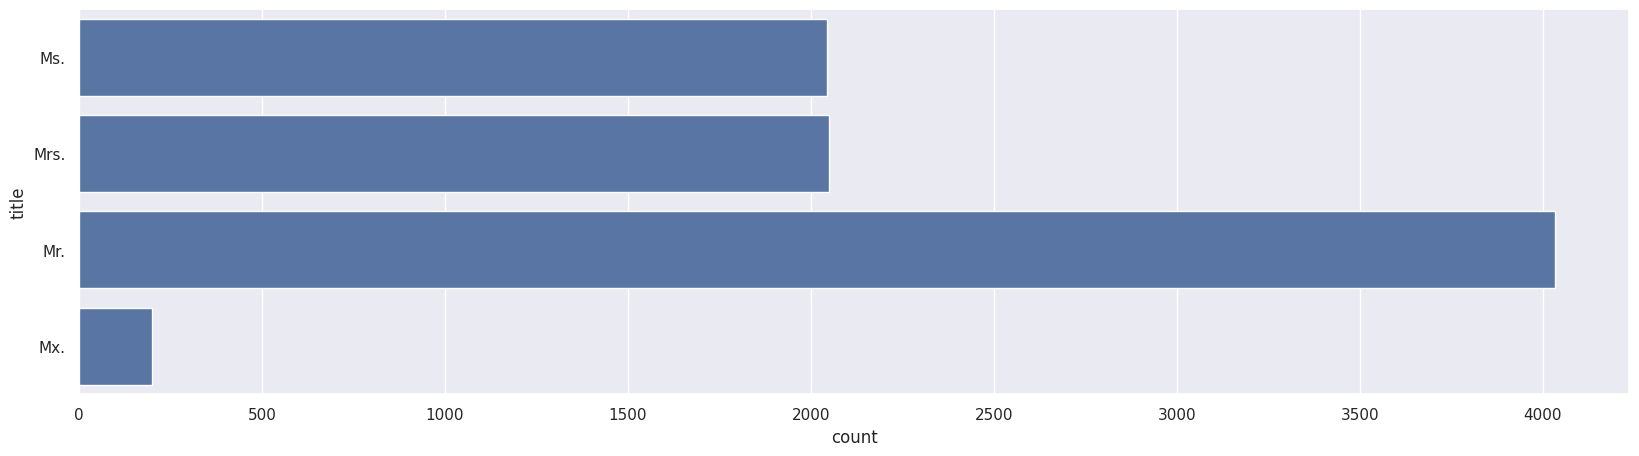

In [23]:
#variable bar chart

plt.figure(figsize=(20,5))
sns.countplot(wd_ct['title'])
plt.show()

In [24]:
#total of each title

print(f"Number of Mr.: {wd_ct['title'].value_counts()['Mr.']}")
print(f"Number of Mrs.: {wd_ct['title'].value_counts()['Mrs.']}")
print(f"Number of Ms.: {wd_ct['title'].value_counts()['Ms.']}")
print(f"Number of Mx.: {wd_ct['title'].value_counts()['Mx.']}")

Number of Mr.: 4034
Number of Mrs.: 2049
Number of Ms.: 2044
Number of Mx.: 200


"Title" is a variable that tells us the marital status of women (or possibly misleads us, as "Ms." may also be used by women who choose to conceal it), but nothing about the other members of the dataset. Thus, to avoid drawing wrong conclusions or focusing more on one gender on the clustering phase, we decided to replace it with a new dummy variable which simply gives the gender of each individual in the dataset.

###Actions on the data

In [25]:
title_gender_map = {
            "Ms.": "Female",
            "Mrs.": "Female",
            "Mr.": "Male",
            "Mx.": "Other"
        }

# Map titles to gender
wd_ct['gender'] = wd_ct['title'].map(title_gender_map)

# Create dummy variables: is_male and is_female
wd_ct['Is_male'] = (wd_ct['gender'] == 'Male').astype(int)
wd_ct['Is_female'] = (wd_ct['gender'] == 'Female').astype(int)

In [26]:
#count how many male and female individuals we have after the changes

print(f"Number of males: {wd_ct['Is_male'].sum()}")
print(f"Number of females: {wd_ct['Is_female'].sum()}")

Number of males: 4034
Number of females: 4093


In [27]:
#drop the variable title
wd_ct.drop('title', axis=1, inplace=True)

##Age

(date of birth)

###Details and visuals

In [28]:
#checking for missing values

wd_ct['date_of_birth'].isna().sum()
print(f"Number of missing values: {wd_ct['date_of_birth'].isna().sum()}")

Number of missing values: 0


In [29]:
#basic statistics

wd_ct['date_of_birth'].describe()

,date_of_birth
count,8327
mean,1988-07-11 03:27:10.311036416
min,1910-01-04 00:00:00
25%,1981-02-11 00:00:00
50%,1990-01-21 00:00:00
75%,1997-09-06 00:00:00
max,2024-12-07 00:00:00


In [30]:
# Datetime library contains the function date.timetoday() which contains today's date
from datetime import datetime


older = wd_ct['date_of_birth'].min()
younger = wd_ct['date_of_birth'].max()
older_age = (datetime.today() - older).days // 365
print(f'The oldest person is {older_age} years old')
younger_age_years = (datetime.today() - younger).days // 365
younger_age_months = (datetime.today() - younger).days % 365 // 30
print(f'The youngest person is {younger_age_months} months old')

The oldest person is 115 years old
The youngest person is 6 months old


<Axes: xlabel='date_of_birth', ylabel='Count'>

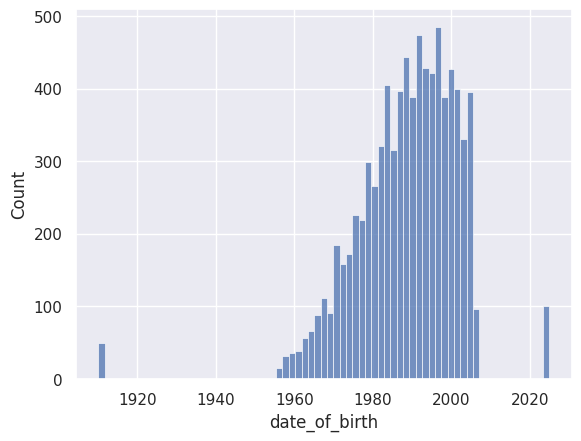

In [31]:
#date of birth histogram

sns.histplot(wd_ct['date_of_birth'])

<Axes: ylabel='date_of_birth'>

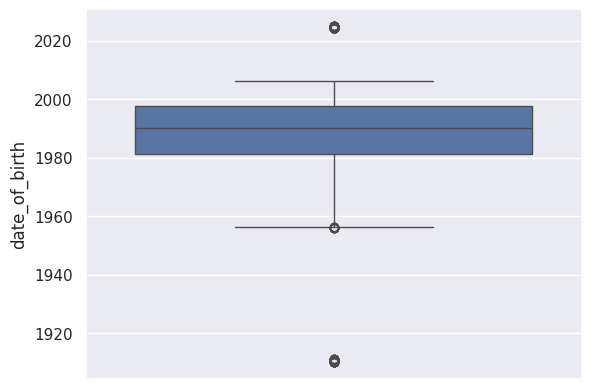

In [32]:
#variable boxplot

sns.boxplot(wd_ct['date_of_birth'])

###Sugested alterations

Having nearly 50 people who are 115 years old in a dataset with little more than 8300 individuals seems too unlikely, while on the other hand babies cannot really be considered to have a lifestyle. Thus, we removed these outliers
(people too old or too young) who would just disturb the model.

In [33]:
#identifying the outliers

r1 = wd_ct[wd_ct['date_of_birth'] <= '1940-01-01'].shape[0]
r2 = wd_ct[wd_ct['date_of_birth'] > '2020-01-01'].shape[0]
tr = r1 + r2
pr = (tr*100) / wd_ct.shape[0]
print(f'total:{tr} and {pr}%')

total:150 and 1.8013690404707579%


<Axes: ylabel='date_of_birth'>

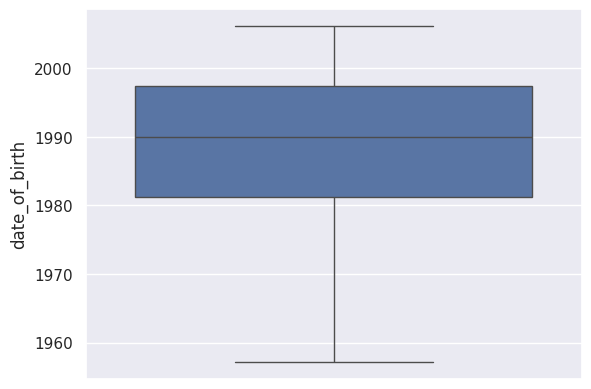

In [34]:
#removing the outliers

wd_ct = wd_ct.drop(wd_ct[wd_ct['date_of_birth'] < '1957-01-01'].index)
wd_ct = wd_ct.drop(wd_ct[wd_ct['date_of_birth'] > '2020-01-01'].index)
sns.boxplot(wd_ct['date_of_birth'])

Turning date of birth into age for reduced complexity

In [35]:
wd_ct['age'] = (datetime.today() - wd_ct['date_of_birth']).dt.days // 365
wd_ct.drop(columns=['date_of_birth'], inplace=True)


##City

(city)

###Analysis and visuals

#### 3684 Different cities + 8 missing values

In [36]:
#basic statistics

wd_ct['city'].describe()

,city
count,8160
unique,3684
top,Tauranga
freq,24


In [37]:
#the different cities in the dataset

a = 1
for i in wd_ct['city'].unique():
  print(f'{a}: {i}')
  a += 1

1: Palmas
2: Taupo
3: Nauen
4: Kusel
5: Rize
6: Ú©Ø±Ù…Ø§Ù†Ø´Ø§Ù‡
7: Rheeze
8: Chelsea
9: Carrick-on-Suir
10: Cardiff
11: Roscommon
12: Tramore
13: Manchester
14: Koudum
15: Bhiwandi
16: Schwandorf
17: Ú¯Ù„Ø³ØªØ§Ù†
18: Reims
19: Vranje
20: Pallavaram
21: Marrum
22: Kiiminki
23: Ã„Ã¤nekoski
24: Bobrovicya
25: JÃ¤mijÃ¤rvi
26: PoÃ§os de Caldas
27: Noviy Rozdil
28: SchÃ¶nebeck (Elbe)
29: Tecumseh
30: Masterton
31: Termunten
32: Mulhouse
33: BrÃ¸ndby Strand
34: Kempele
35: Sotkamo
36: Angerlo
37: Nowra
38: Sidney
39: LuÄani
40: Tatarbunari
41: VÃ¥re
42: Torrente
43: Lieberose
44: Nelson
45: Grenoble
46: Warrnambool
47: Garmerwolde
48: Dorchester
49: Eernewoude
50: PÃ¶ytyÃ¤
51: Renbygda
52: Porirua
53: Kristiansand
54: VitÃ³ria
55: Dibrugarh
56: Inverness
57: La CoruÃ±a
58: BeitostÃ¸len
59: Amaravati
60: Celbridge
61: ChÃ¢tel-Saint-Denis
62: Yozgat
63: Vitoria
64: Eriz
65: Stoevring
66: Kalgoorlie
67: Duggingen
68: MÃ³stoles
69: Vang
70: Boulogne-Billancourt
71: Mogi das Cruzes
72: RistijÃ¤r

In [38]:
#checking for missing values

wd_ct['city'].isna().sum()
print(f"Number of missing values: {wd_ct['city'].isna().sum()}")

Number of missing values: 0


In [39]:
#From the excel we concluded that the missing values in this collumn where represented as '?'
wd_ct['city'].isin(['?']).sum()
print(f"Number of missing values: {wd_ct['city'].isin(['?']).sum()}")

Number of missing values: 8


###Sugestions

This column, due to its high variety of categories (cities) adds no relevant information to the process, so we decided to exclude it from the model.

In [40]:
wd_ct = wd_ct.drop('city', axis=1)

##Country

(country)

###Analysis and visuals

In [41]:
#basic statistics

wd_ct['country'].describe()

,country
count,8160
unique,22
top,Spain
freq,438


In [42]:
#different countries in the dataset

a = 1
for i in wd_ct['country'].unique():
  print(f'{a}: {i}')
  a += 1

1: Brazil
2: New Zealand
3: Germany
4: Turkey
5: Iran
6: Netherlands
7: Canada
8: Ireland
9: United Kingdom
10: India
11: France
12: Serbia
13: Finland
14: Ukraine
15: Denmark
16: Australia
17: Norway
18: Spain
19: Switzerland
20: Mexico
21: United States
22:   


In [43]:
#checking for missing values

wd_ct['country'].isna().sum()

np.int64(0)

There are blanks that a system does not considerate missing values? Spaces maybe?

We need to change this somehow

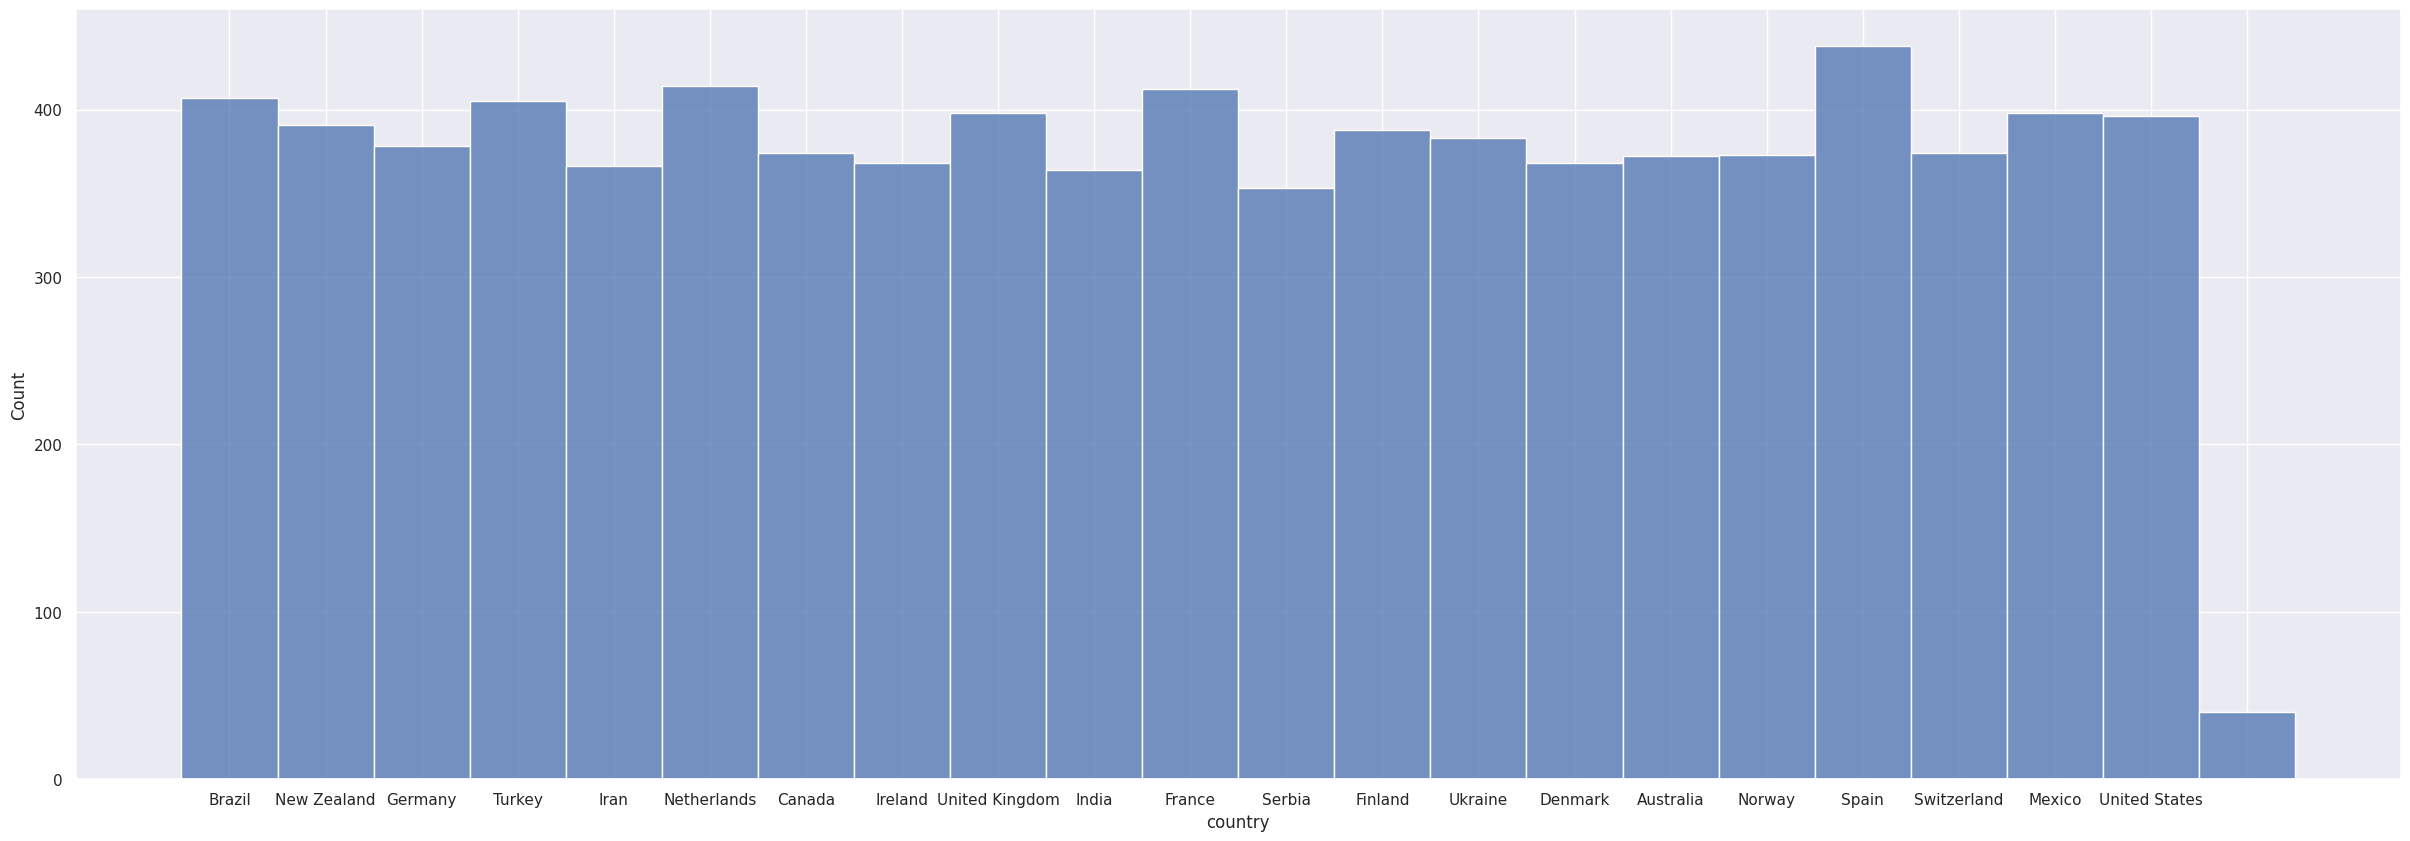

In [44]:
#variable bar chart

plt.figure(figsize=(30, 10))
sns.histplot(wd_ct['country'])
plt.show()

###Alterations/suggestions

Replacing blanks by actual missing values

Why:
1.   It helps the algorithms to be more accurate
2.   That way we can replace later the values using a predictive algorithm



In [45]:
wd_ct['country'] = wd_ct['country'].replace('  ', np.nan)
wd_ct['country'].isna().sum()

np.int64(40)

##Last year donations to charity

###Analysis and visualizations

In [46]:
#here we converted the variable to unit dollars($) before proceding with the preprocessing and visualizations

wd_ct['last_year_charity_donations'] = wd_ct['last_year_charity_donations'] * 1000

In [47]:
#basic statistics

print(wd_ct['last_year_charity_donations'].describe())

count    8036.000000
mean      381.738265
std       765.476779
min         0.000000
25%         0.000000
50%        10.400000
75%       310.425000
max      5599.100000
Name: last_year_charity_donations, dtype: float64


In [48]:
#checking for missing values

print(f'Missing values: {wd_ct["last_year_charity_donations"].isna().sum()}')

Missing values: 124


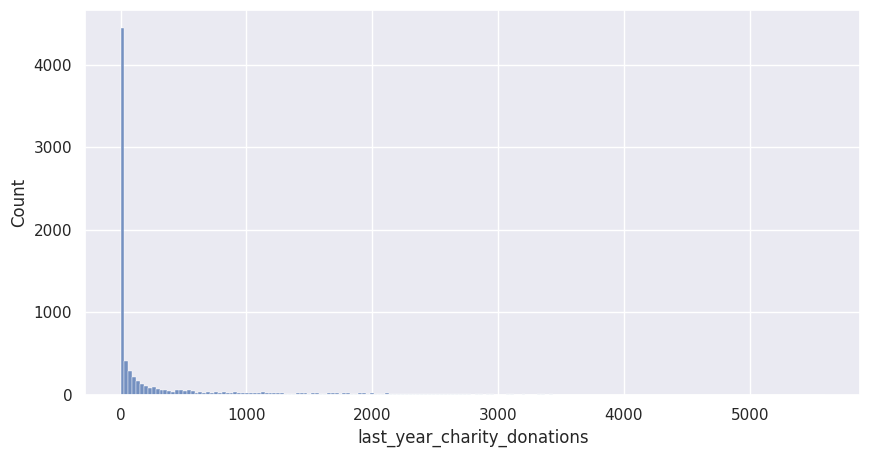

In [49]:
#variable histogram

plt.figure(figsize=(10, 5))
sns.histplot(wd_ct['last_year_charity_donations'])
plt.show()

<Axes: xlabel='last_year_charity_donations'>

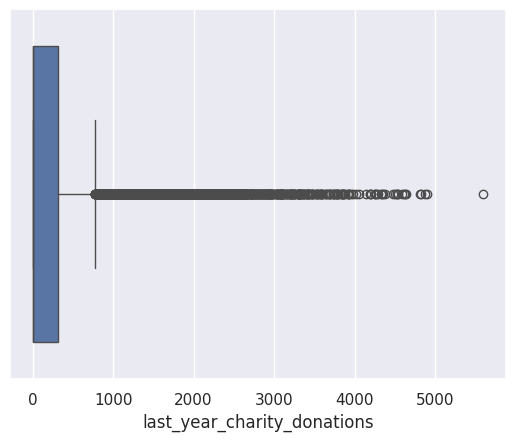

In [50]:
#variable boxplot

sns.boxplot(x=wd_ct['last_year_charity_donations'])

In [51]:
#number of outliers for this variable

print(f"Number of outliers: {find_outliers(wd_ct['last_year_charity_donations']).shape[0]}")

Number of outliers: 1364


This variable, due to the heavy presence of 0 values (people with no donations)will naturally have a significant number of outliers, yet it may provide useful insights when applying the model, so we decide to leave it as it is.

###Alterations/suggestions

Create a new binary collum, which contains only the fact wherether someone donated or not to charity

Note: it is not used for the descriptive model, but may be used for the predictive model

In [52]:
wd_ct['donates'] = wd_ct['last_year_charity_donations'].apply(lambda x: 1 if x != 0 else 0)
# 1 is True (donated) 0 is false (did not donate)

In [53]:
wd_ct['donates'].head(6)

,donates
0,0
1,0
2,0
3,1
4,0
5,1


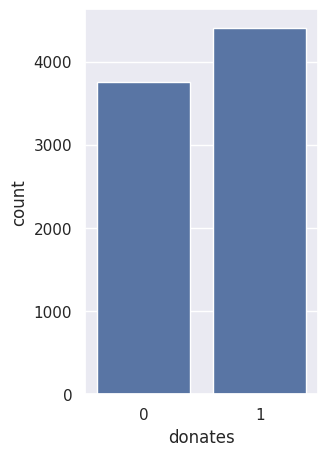

In [54]:
#variable bar chart

plt.figure(figsize=(3, 5))
sns.countplot(x=wd_ct['donates'])
plt.show()

##Environmental Awareness Rating

(environmental_awareness_rating)

###Analysis and Visuals

In [55]:
#basic statistics

wd_ct['environmental_awareness_rating'].describe()

,environmental_awareness_rating
count,8129.000000
mean,0.827523
std,0.650787
min,0.037600
25%,0.540900
50%,0.631200
75%,0.774600
max,7.402500


In [56]:
#checking for missing values

print(f'Missing values: {wd_ct["environmental_awareness_rating"].isna().sum()}')

Missing values: 31


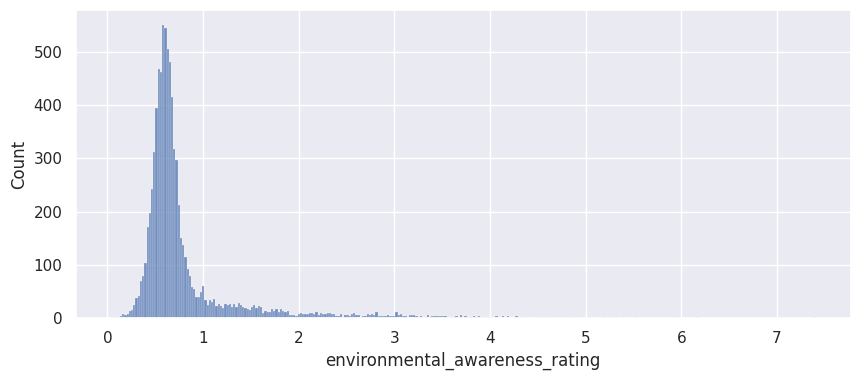

In [57]:
#variable histogram

plt.figure(figsize=(10, 4))
sns.histplot(wd_ct['environmental_awareness_rating'])
plt.show()

<Axes: xlabel='environmental_awareness_rating'>

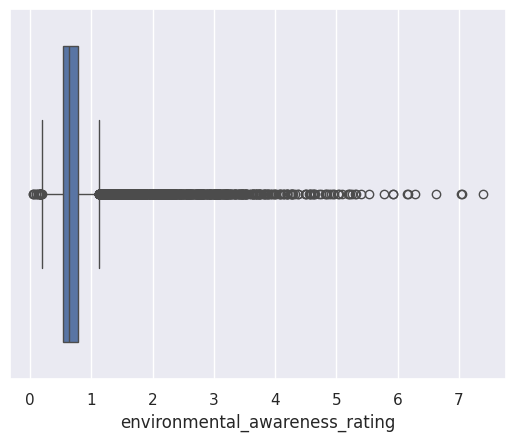

In [58]:
#variable boxplot

sns.boxplot(x=wd_ct['environmental_awareness_rating'])

In [59]:
find_outliers(wd_ct['environmental_awareness_rating']).shape[0]

1143

<Axes: xlabel='environmental_awareness_rating', ylabel='Count'>

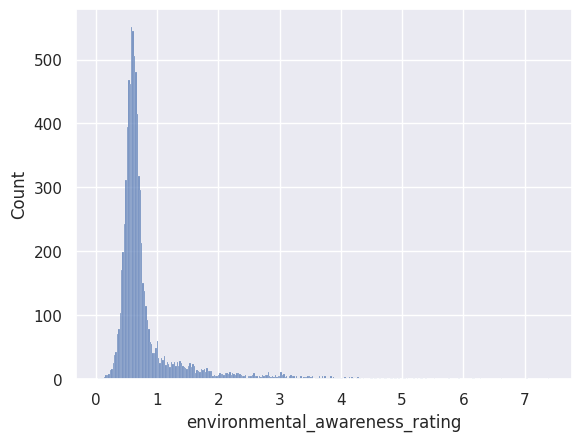

In [60]:
sns.histplot(wd_ct['environmental_awareness_rating'])

###Sugestions/Alterations

To correct skewness in the distribution, we decided to apply a logarithmic transformation.

In [61]:
wd_ct['log_environmental_awareness_rating'] = np.log(wd_ct['environmental_awareness_rating'] + 1)
#drop the old column
wd_ct = wd_ct.drop('environmental_awareness_rating', axis=1)

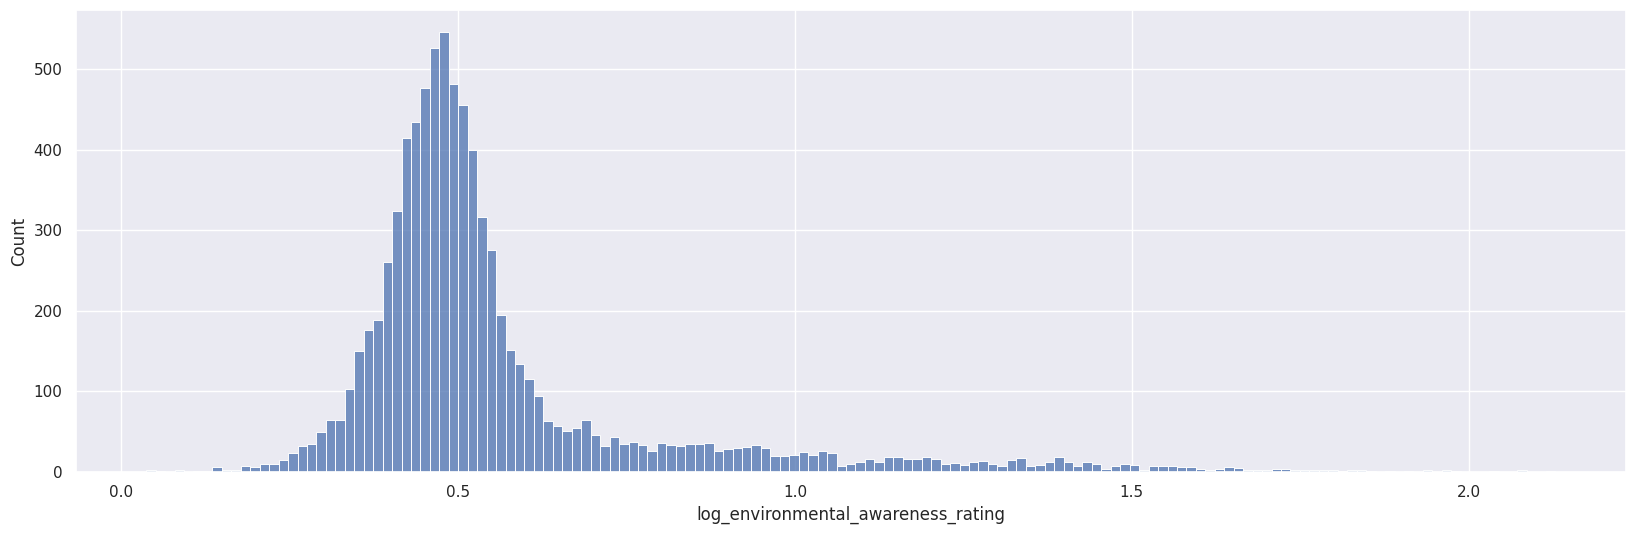

In [62]:
#variable histogram after log transformation

plt.figure(figsize=(20,6))
sns.histplot(wd_ct['log_environmental_awareness_rating'])
plt.show()

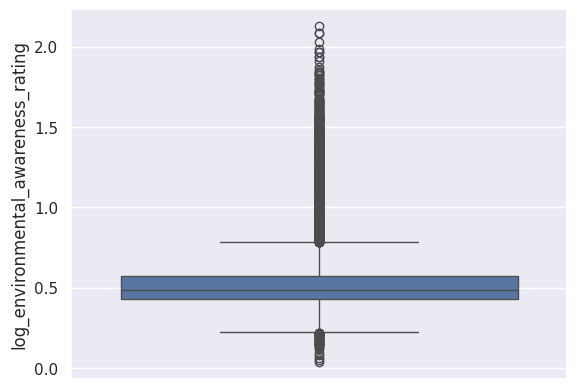

In [63]:
#variable boxplot after log transformation

sns.boxplot(wd_ct['log_environmental_awareness_rating'])
plt.show()

In [64]:
#basic statistics after log transformation

wd_ct['log_environmental_awareness_rating'].describe()

,log_environmental_awareness_rating
count,8129.000000
mean,0.563643
std,0.252084
min,0.036910
25%,0.432367
50%,0.489316
75%,0.573575
max,2.128529


In [65]:
#checking for outliers after log transformation

find_outliers(wd_ct['log_environmental_awareness_rating']).shape[0]

1094

<Axes: xlabel='log_environmental_awareness_rating', ylabel='Count'>

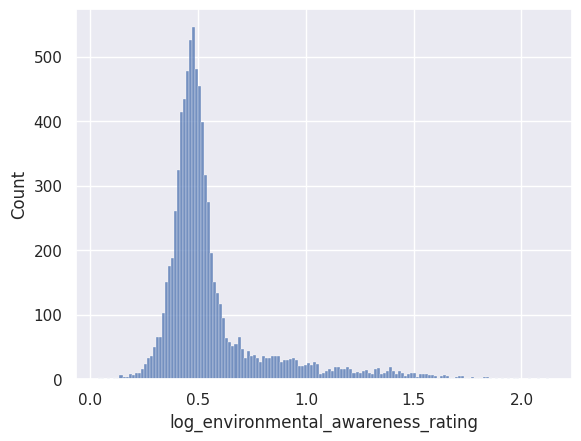

In [66]:
sns.histplot(wd_ct['log_environmental_awareness_rating'])

<Axes: ylabel='log_environmental_awareness_rating'>

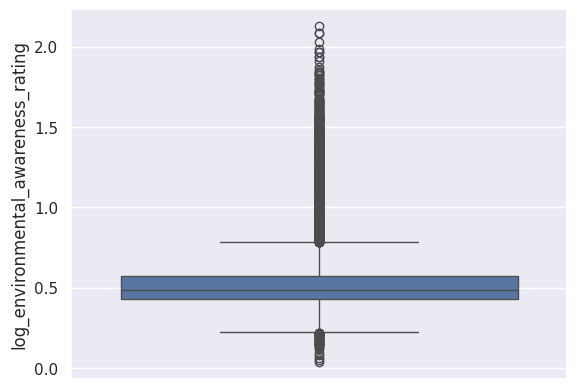

In [67]:
sns.boxplot(wd_ct['log_environmental_awareness_rating'])

With the transformation, we slightly decreased the number of outliers and managed to make the distribution a bit more normalized.

##Financial

(financial_wellness_index)

###Analysis and visuals

In [68]:
#basic statistics

print(wd_ct['financial_wellness_index'].describe())

count    7914.000000
mean      106.331198
std        64.390470
min        -0.050000
25%        87.056250
50%        99.801100
75%       113.914750
max       458.451000
Name: financial_wellness_index, dtype: float64


In [69]:
#checking for missing values

print(f'Missing Values: {wd_ct["financial_wellness_index"].isna().sum()}')

Missing Values: 246


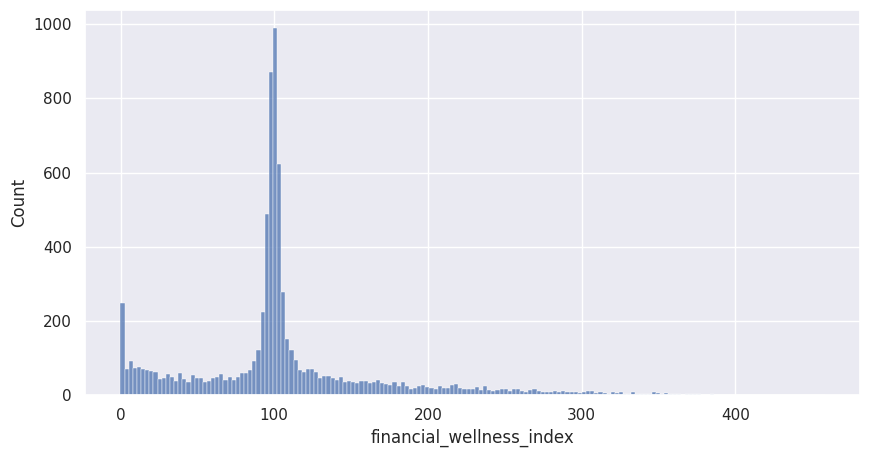

In [70]:
#variable histogram

plt.figure(figsize=(10, 5))
sns.histplot(wd_ct['financial_wellness_index'])
plt.show()

<Axes: xlabel='financial_wellness_index'>

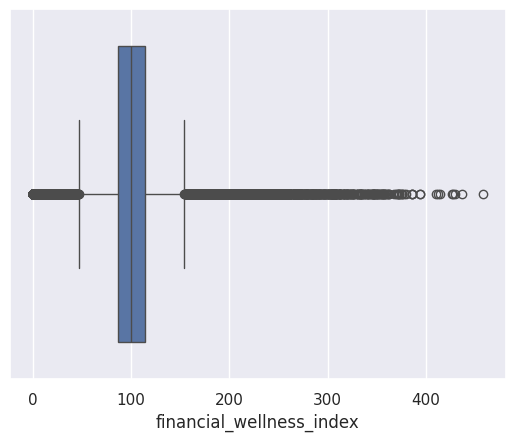

In [71]:
#variable boxplot

sns.boxplot(x=wd_ct['financial_wellness_index'])

<Axes: xlabel='financial_wellness_index', ylabel='Count'>

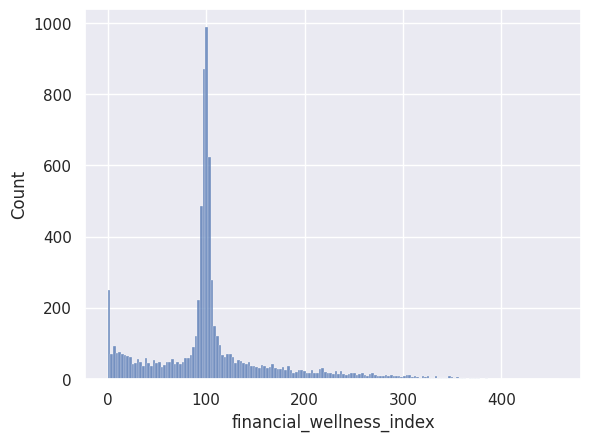

In [72]:
sns.histplot(wd_ct['financial_wellness_index'])

In [73]:
#checking for outliers
print(f"Number of outliers: {find_outliers(wd_ct['financial_wellness_index']).shape[0]}")

Number of outliers: 2408


###Alterations/Sugestions

Considering the scale of this variable, negative values don't appear to be much logic in this case, thus since there weren't that many we converted them into 0. We also considered applying a transformation, but since the variable wasn't that skewed it did not show any meaningful or useful change.

In [74]:
#Make everything lower than 0 became 0
wd_ct['financial_wellness_index'] = wd_ct['financial_wellness_index'].apply(lambda x: 0 if x < 0 else x)

<Axes: xlabel='financial_wellness_index', ylabel='Count'>

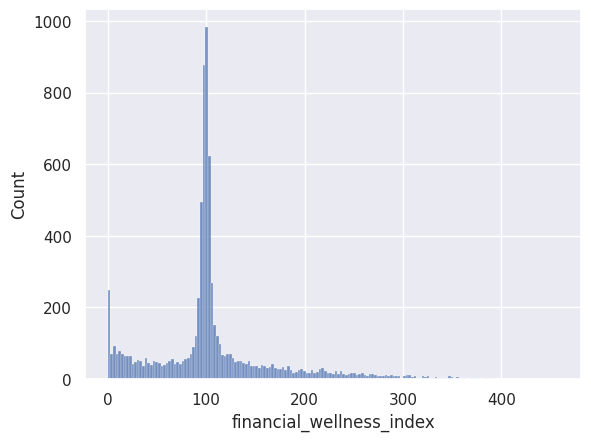

In [75]:
sns.histplot(wd_ct['financial_wellness_index'])

##Investment

###Portfolio

investment_portfolio_value

####Analysis and visuals

In [76]:
#basic statistics

print(wd_ct['investment_portfolio_value'].describe())

count    8038.000000
mean       12.418881
std        21.242266
min         0.000000
25%         3.294850
50%         8.594950
75%        13.259900
max       294.950000
Name: investment_portfolio_value, dtype: float64


In [77]:
#checking for missing values

print(f'Missing Values: {wd_ct["investment_portfolio_value"].isna().sum()}')

Missing Values: 122


In [78]:
#here we converted the variable to unit dollars($) before proceding with the preprocessing and visualizations

wd_ct['investment_portfolio_value'] = wd_ct['investment_portfolio_value'] * 1000

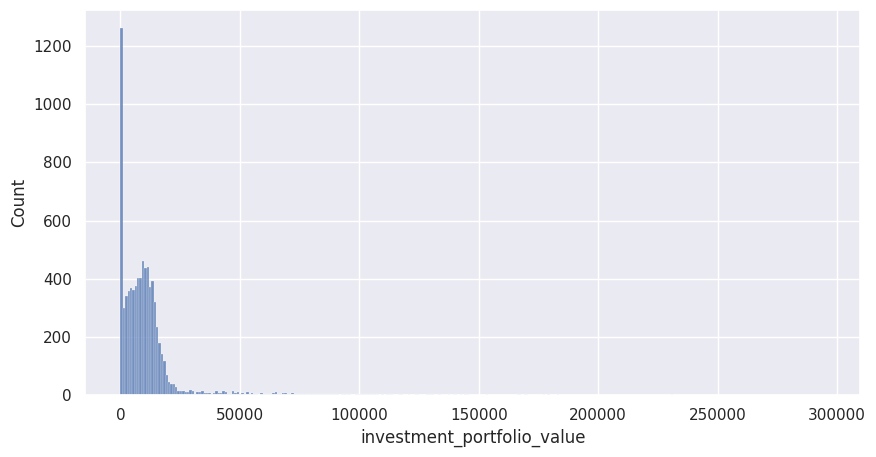

In [79]:
#variable histogram

plt.figure(figsize=(10,5))
sns.histplot(wd_ct['investment_portfolio_value'])
plt.show()

<Axes: ylabel='investment_portfolio_value'>

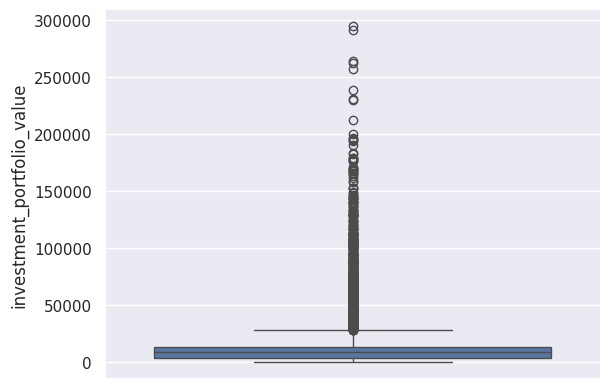

In [80]:
#variable boxplot

sns.boxplot(wd_ct['investment_portfolio_value'])

In [81]:
#checking for outliers

print(f"Number of outliers: {find_outliers(wd_ct['investment_portfolio_value']).shape[0]}")

Number of outliers: 512


####Alterations/suggestions

We applied a log transformation here to correct skewness.

In [82]:
#Add 1 to every observation and then do the log of the column to keep the minimum of the scale at 0
wd_ct['log_investment_portfolio_value'] = np.log(wd_ct['investment_portfolio_value'] + 1)

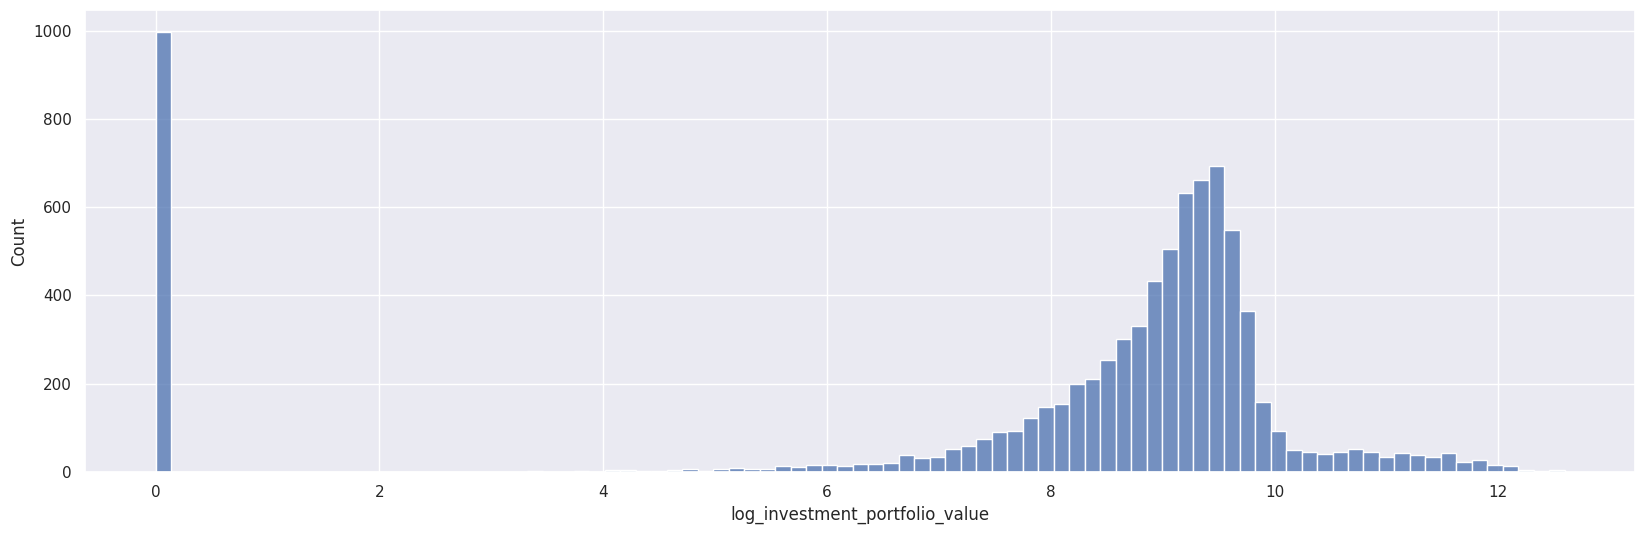

In [83]:
#variable histogram after log transformation

plt.figure(figsize=(20,6))
sns.histplot(wd_ct['log_investment_portfolio_value'])
plt.show()

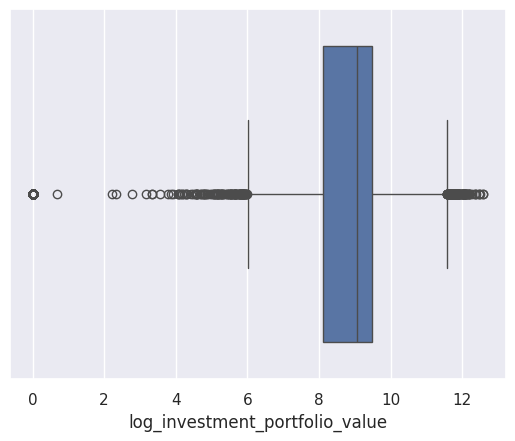

In [84]:
#variable boxplot after log transformation

boxplot = sns.boxplot(x=wd_ct['log_investment_portfolio_value'])

In [85]:
#checking for outliers

print(f"Number of outliers: {find_outliers(wd_ct['log_investment_portfolio_value']).shape[0]}")

Number of outliers: 1217


We decided to create a new variable that divides investors in 3 bins:

No investor = 0

Common Investor < 13259.900

Strong investor > 13259.900

Like previously with the "donates" variable, this variable will not be used yet for the descriptive model.

In [86]:
#creating the "is_investor" variable

wd_ct['is_investor'] = wd_ct['investment_portfolio_value'].apply(lambda x: 'No' if x == 0 else 'Common' if 0 < x < 13259.900 else 'Strong')

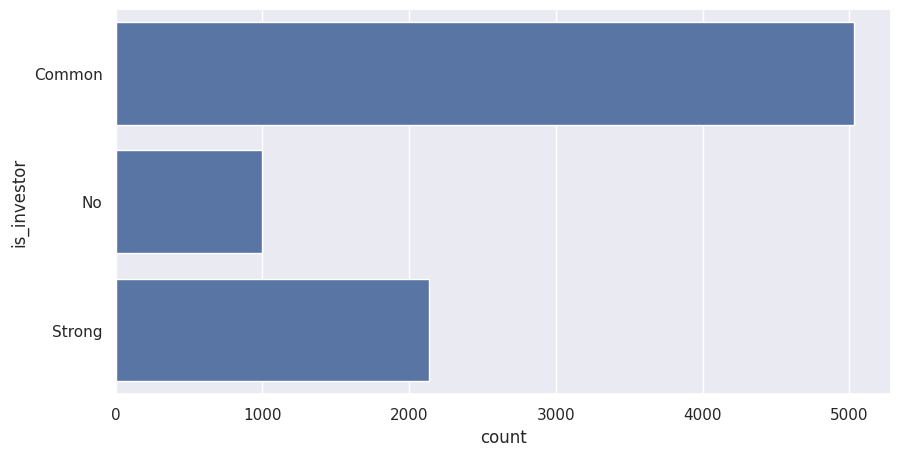

In [87]:
#new variable bar chart

plt.figure(figsize=(10,5))
sns.countplot(wd_ct['is_investor'])
plt.show()

In [88]:
#drop the old column
wd_ct = wd_ct.drop('investment_portfolio_value', axis=1)

<Axes: xlabel='log_investment_portfolio_value', ylabel='Count'>

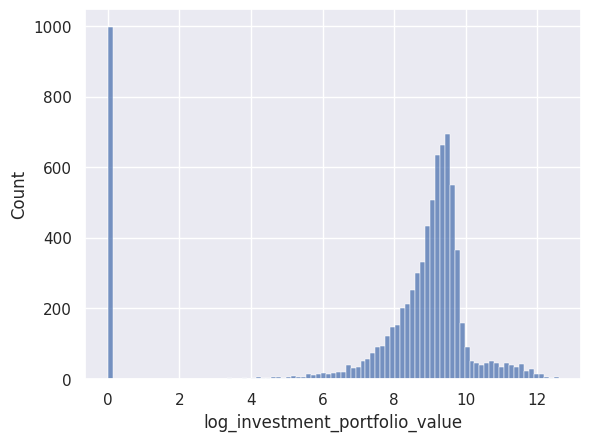

In [89]:
sns.histplot(wd_ct['log_investment_portfolio_value'])

###Risk

In [90]:
#basic statistics

print(wd_ct['investments_risk_appetite'].describe())

count    7914.000000
mean        4.377495
std         2.646780
min         0.000000
25%         1.851350
50%         4.814950
75%         6.875725
max         8.699500
Name: investments_risk_appetite, dtype: float64


In [91]:
#checking for missing values

print(f'Missing Values: {wd_ct["investments_risk_appetite"].isna().sum()}')

Missing Values: 246


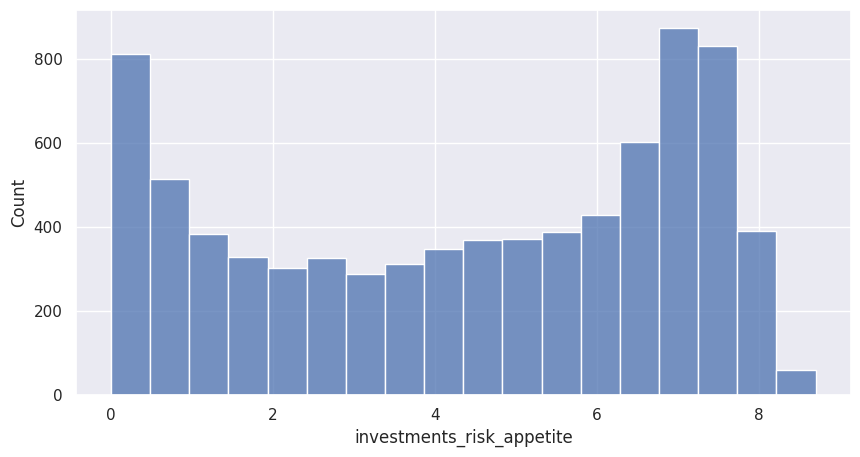

In [92]:
#variable histogram

plt.figure(figsize=(10,5))
sns.histplot(wd_ct['investments_risk_appetite'])
plt.show()

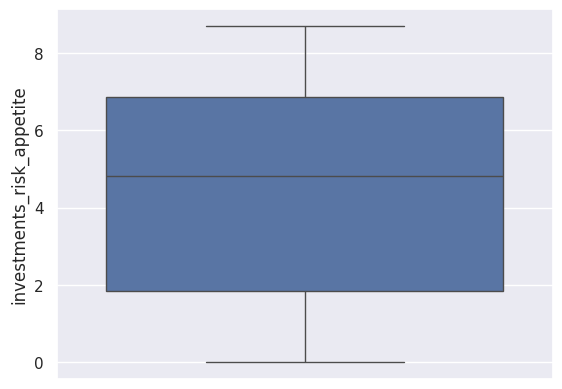

In [93]:
#variable boxplot

sns.boxplot(wd_ct['investments_risk_appetite'])
plt.show()

No changes need to be done to this variable.

###Tolerance

(investments_risk_tolerance)

####Analysis and visuals

In [94]:
#basic statistics

print(wd_ct['investments_risk_tolerance'].describe())

count    8000.000000
mean        7.310148
std         3.682506
min         1.393700
25%         4.797600
50%         6.221850
75%         8.545325
max        29.513200
Name: investments_risk_tolerance, dtype: float64


In [95]:
#checking for missing values

print(f'Missing Values: {wd_ct["investments_risk_tolerance"].isna().sum()}')

Missing Values: 160


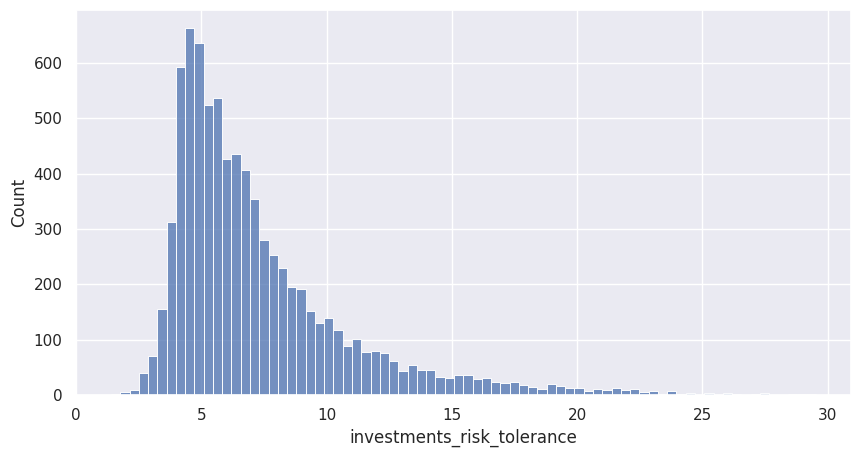

In [96]:
#variable histogram

plt.figure(figsize=(10,5))
sns.histplot(wd_ct['investments_risk_tolerance'])
plt.show()

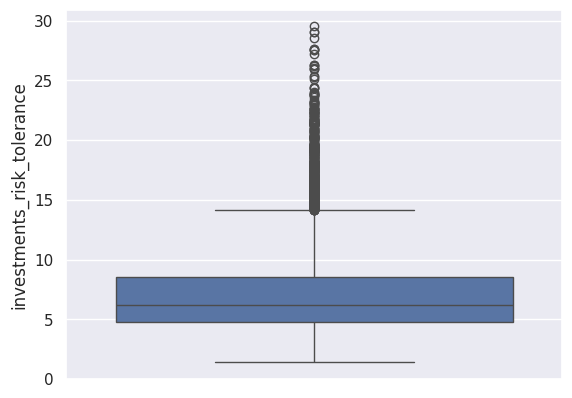

In [97]:
#variable histogram

sns.boxplot(wd_ct['investments_risk_tolerance'])
plt.show()

In [98]:
#checking for outliers

print(f"Number of outliers: {find_outliers(wd_ct['investments_risk_tolerance']).shape[0]}")

Number of outliers: 495


####Alterations/Sugestions

Logarithmic transformation of investments risk tolerance

In [99]:
#transforming the variable

wd_ct['log_investments_risk_tolerance'] = np.log(wd_ct['investments_risk_tolerance'])

#drop the old column

wd_ct = wd_ct.drop('investments_risk_tolerance', axis=1)

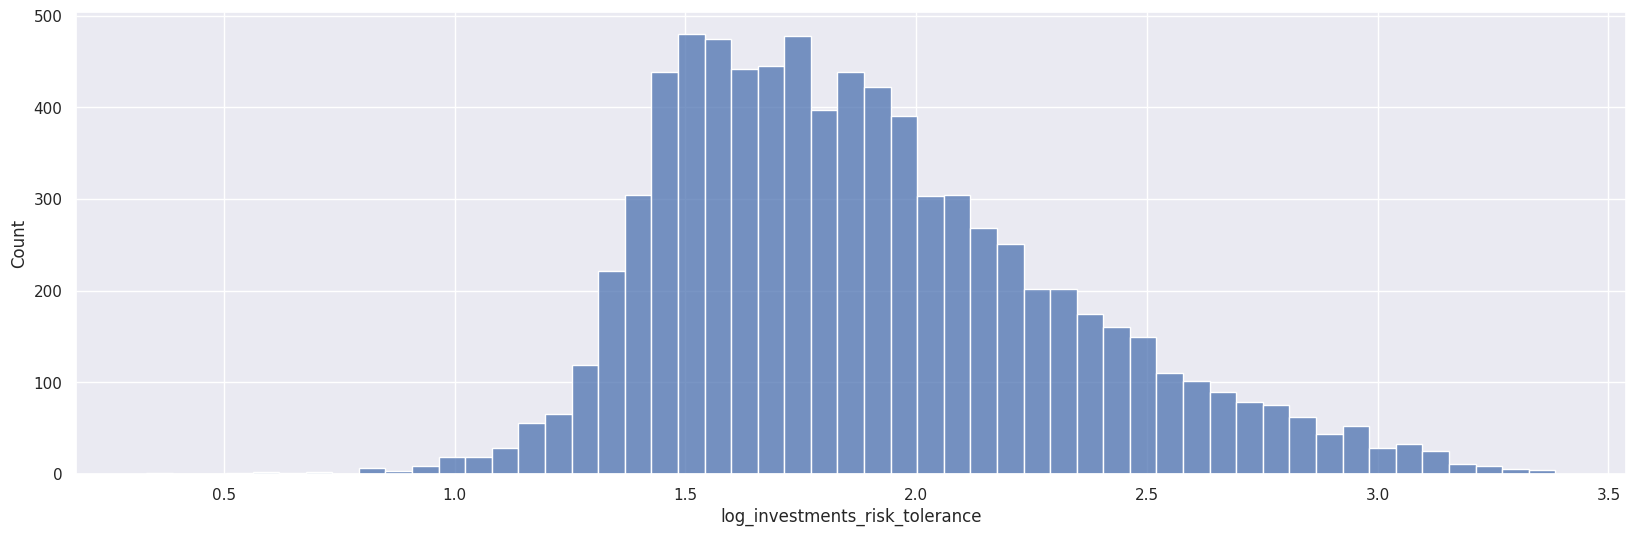

In [100]:
#transformed variable histogram

plt.figure(figsize=(20,6))
sns.histplot(wd_ct['log_investments_risk_tolerance'])
plt.show()

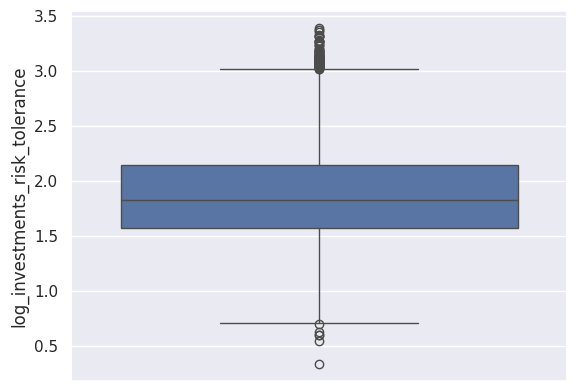

In [101]:
#transformed variable boxplot

sns.boxplot(wd_ct['log_investments_risk_tolerance'])
plt.show()

Once again, the log transformation improved the distribution and reduced the number of outliers.

##Happiness

(hapiness_level)

###Analysis and Visuals

In [102]:
#basic statistics

wd_ct['hapiness_level'].describe()

,hapiness_level
count,8160
unique,1
top,medium
freq,8160


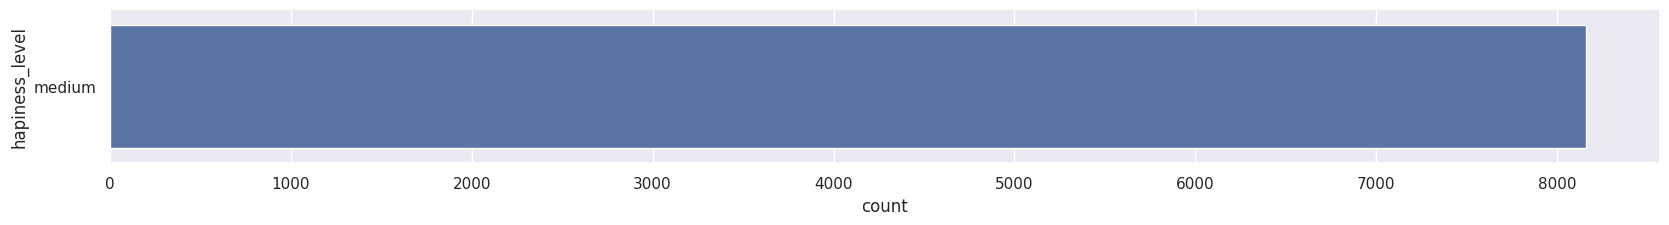

,count
hapiness_level,
medium,8160


In [103]:
#variable bar chart

plt.figure(figsize=(20,2))
sns.countplot(wd_ct['hapiness_level'])
plt.show()
wd_ct['hapiness_level'].value_counts()

###Sugestion/Alteration

Constants add no value to our model.

We decided to drop this variable for this reason.

In [104]:
wd_ct = wd_ct.drop('hapiness_level', axis=1)

##Social media

(social_media_influence_ score)

###Analysis and visuals

In [105]:
#basic statistics

wd_ct['social_media_influence_score'].describe()

,social_media_influence_score
count,8160.000000
mean,6.097162
std,4.325152
min,0.000000
25%,3.166325
50%,4.400600
75%,8.199450
max,42.176800


In [106]:
#checking for missing values

print(f'Missing Values: {wd_ct["social_media_influence_score"].isna().sum()}')

Missing Values: 0


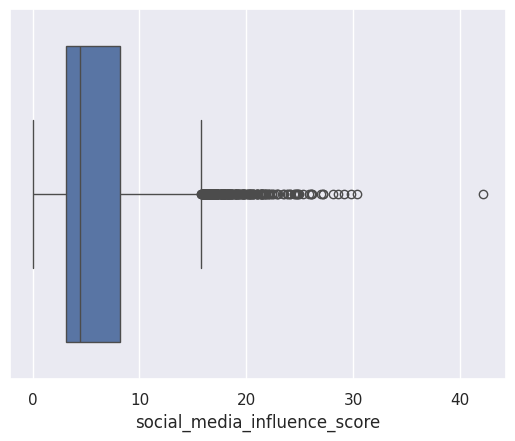

In [107]:
#variable boxplot

boxplot = sns.boxplot(x=wd_ct['social_media_influence_score'])

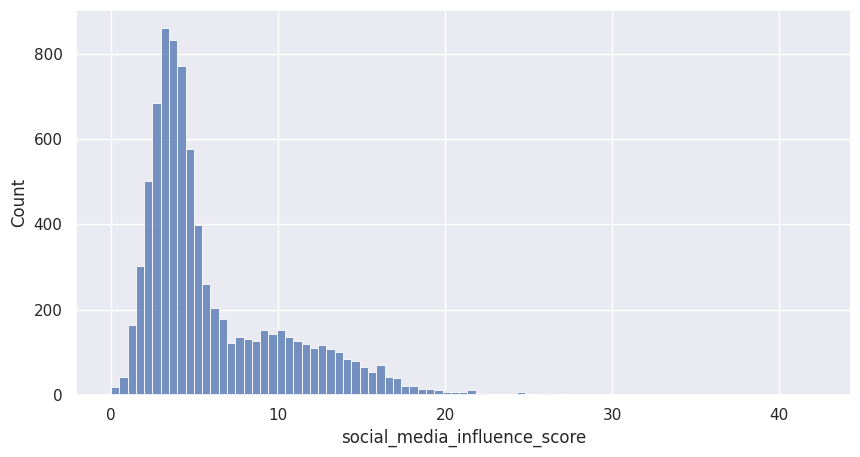

In [108]:
#variable histogram

plt.figure(figsize=(10, 5))
sns.histplot(wd_ct['social_media_influence_score'])
plt.show()

In [109]:
#checking for outliers

find_outliers(wd_ct['social_media_influence_score']).shape[0]

313

###Alterations and sugestions

Drop all observations that are above 40 and once again do a log transformation to the variable.

In [110]:
#dropping values over 40

wd_ct = wd_ct[wd_ct['social_media_influence_score'] <= 40]

In [111]:
#Add 1 and then do the log transformation to avoid negative values
wd_ct['log_social_media_influence_score'] = np.log(wd_ct['social_media_influence_score'] + 1)

<ipython-input-111-201456512>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  wd_ct['log_social_media_influence_score'] = np.log(wd_ct['social_media_influence_score'] + 1)


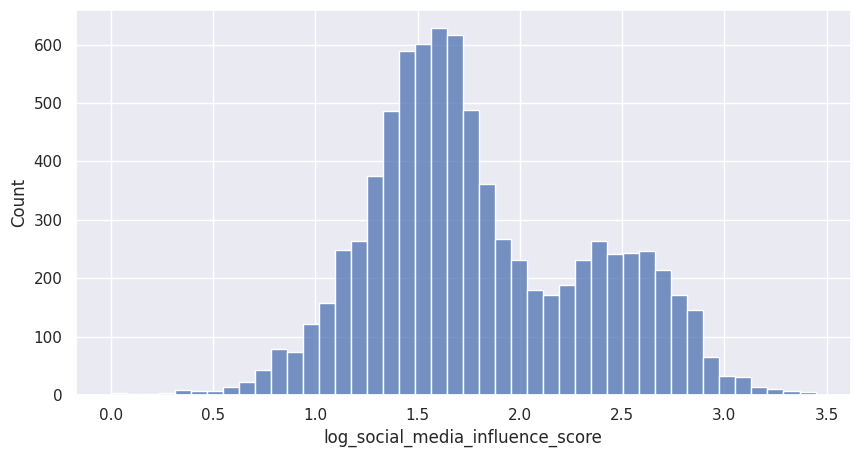

In [112]:
#transformed variable histogram

plt.figure(figsize=(10, 5))
sns.histplot(wd_ct['log_social_media_influence_score'])
plt.show()

<Axes: ylabel='log_social_media_influence_score'>

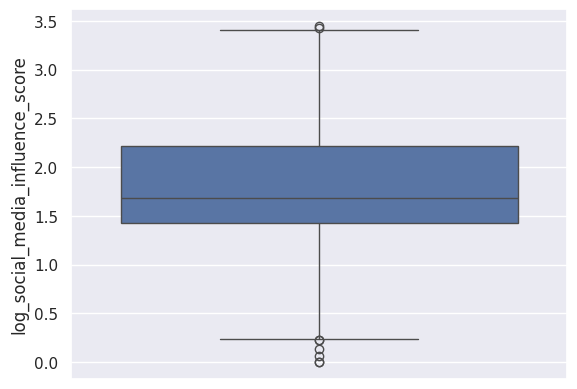

In [113]:
#transformed variable boxplot

sns.boxplot(wd_ct['log_social_media_influence_score'])

In [114]:
#drop the original
wd_ct = wd_ct.drop('social_media_influence_score', axis=1)

Once again, the log transformation improved the distribution and reduced outliers.

##Entertainment expenses

avg_monthly_entertainment_expenses

###Analysis and visuals

In [115]:
#basic statistics

print(wd_ct['avg_monthly_entertainment_expenses'].describe())

count    7914.000000
mean       21.595125
std        17.437764
min         0.000000
25%         8.126575
50%        11.986150
75%        38.779000
max       135.420000
Name: avg_monthly_entertainment_expenses, dtype: float64


In [116]:
#checking for missing values

print(f'Missing Values: {wd_ct["avg_monthly_entertainment_expenses"].isna().sum()}')

Missing Values: 245


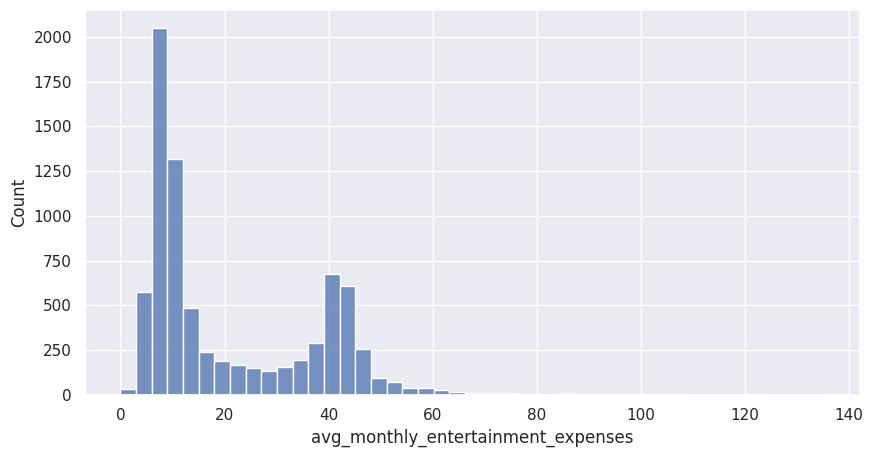

In [117]:
#variable histogram

plt.figure(figsize=(10,5))
sns.histplot(wd_ct['avg_monthly_entertainment_expenses'])
plt.show()

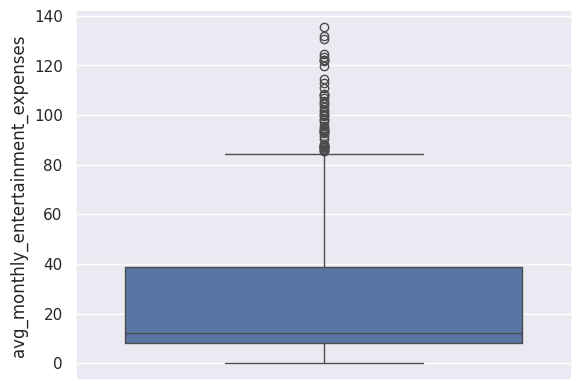

In [118]:
#variable boxplot

sns.boxplot(wd_ct['avg_monthly_entertainment_expenses'])
plt.show()

In [119]:
#checking for outliers

find_outliers(wd_ct['avg_monthly_entertainment_expenses']).shape[0]

51

###Alterations&suggestions

Another variable where we can do a log transformation.

In [120]:
#log tranformation adding 1 to keep 0 as the base of the scale
wd_ct['log_avg_monthly_entertainment_expenses'] = np.log(wd_ct['avg_monthly_entertainment_expenses'] + 1)

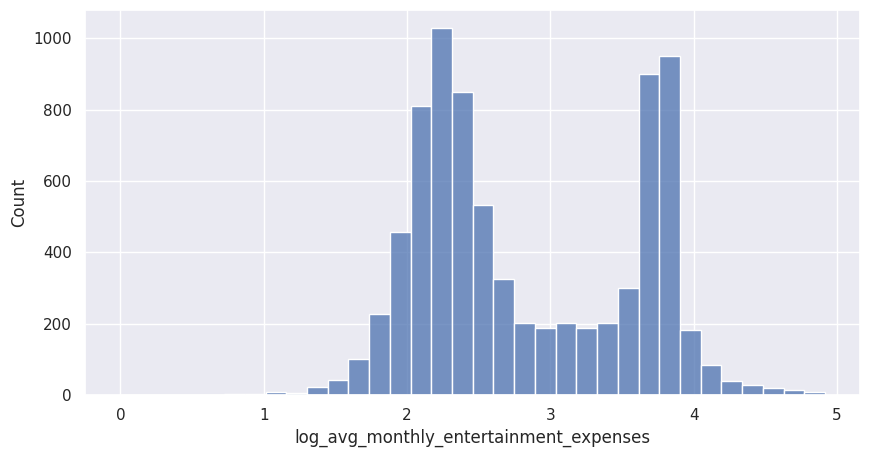

In [121]:
#transformed variable histogram

plt.figure(figsize=(10,5))
sns.histplot(wd_ct['log_avg_monthly_entertainment_expenses'])
plt.show()

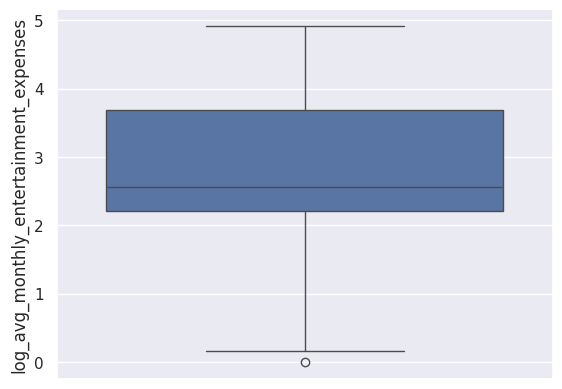

In [122]:
#transformed variable boxplot

sns.boxplot(wd_ct['log_avg_monthly_entertainment_expenses'])
plt.show()

In [123]:
#checking for outliers after the log transformation

find_outliers(wd_ct['log_avg_monthly_entertainment_expenses']).shape[0]

1

In [124]:
#drop the original
wd_ct = wd_ct.drop('avg_monthly_entertainment_expenses', axis=1)

Once again, the log transformation improved the distribution and reduced outliers.

##Exercise

(avg_weekly_exercise_hours)

###Visuals and analysis

In [125]:
#basic statistics

wd_ct['avg_weekly_exercise_hours'].describe()

,avg_weekly_exercise_hours
count,7952.000000
mean,0.705668
std,1.183083
min,-5.579400
25%,0.022400
50%,0.109150
75%,1.023275
max,8.701700


In [126]:
#checking for missing values

wd_ct['avg_weekly_exercise_hours'].isna().sum()

np.int64(207)

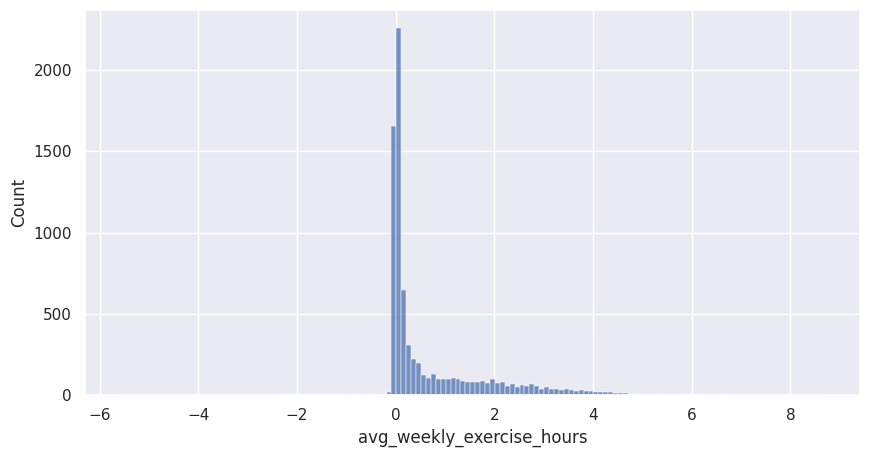

In [127]:
#variable histogram

plt.figure(figsize=(10,5))
sns.histplot(data = wd_ct, x = wd_ct['avg_weekly_exercise_hours'])
plt.show()

<Axes: ylabel='avg_weekly_exercise_hours'>

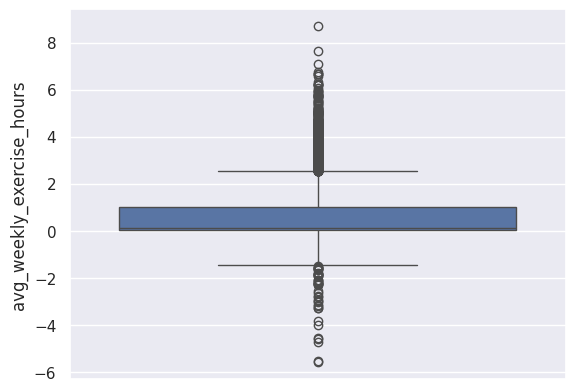

In [128]:
#variable boxplot

sns.boxplot(wd_ct['avg_weekly_exercise_hours'])

In [129]:
#checking for outliers

find_outliers(wd_ct['avg_weekly_exercise_hours']).shape[0]

829

###Sugestions and alterations

Transform negative values into 0, since it is impossible to practice exercise for negative time.

In [130]:
#transform negative values into 0, since it is impossible to practice exercise for negative time.

wd_ct['avg_weekly_exercise_hours'] = wd_ct['avg_weekly_exercise_hours'].apply(lambda x: 0 if x < 0 else x)

In [131]:
#add 1 and do the log transformation
wd_ct['log_avg_weekly_exercise_hours'] = np.log(wd_ct['avg_weekly_exercise_hours'] + 1)

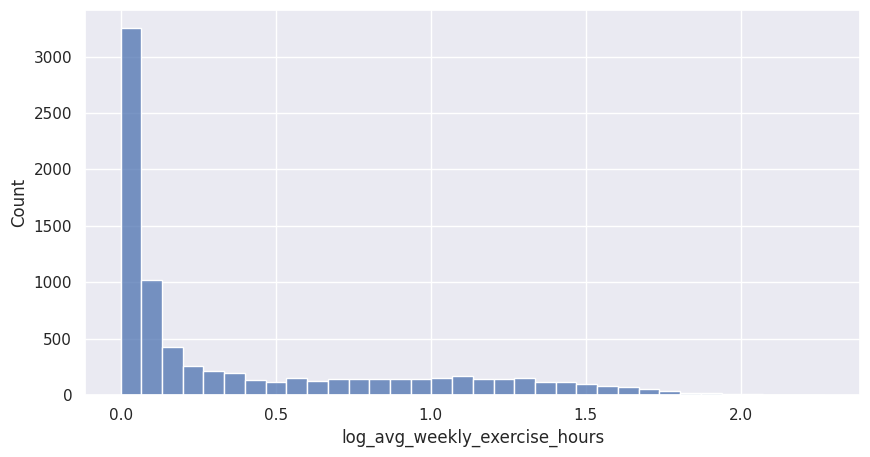

In [132]:
#transformed variable histogram

plt.figure(figsize=(10,5))
sns.histplot(wd_ct['log_avg_weekly_exercise_hours'])
plt.show()

<Axes: ylabel='log_avg_weekly_exercise_hours'>

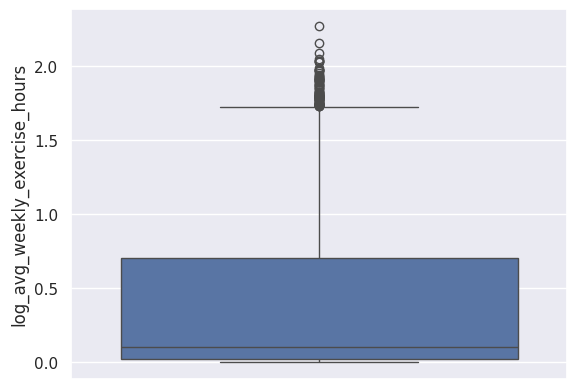

In [133]:
#transformed variable boxplot

sns.boxplot(wd_ct['log_avg_weekly_exercise_hours'])

In [134]:
#drop the original
wd_ct = wd_ct.drop('avg_weekly_exercise_hours', axis=1)

Once again, the log transformation improved the distribution and reduced outliers.

##Health consciousness

(health_consciousness_rating)

###Analysis and visuals

In [135]:
#basic statistics

print(wd_ct['health_consciousness_rating'].describe())

count    7922.000000
mean        1.451822
std         1.396257
min         0.000000
25%         0.685800
50%         0.806250
75%         1.761125
max        10.053000
Name: health_consciousness_rating, dtype: float64


In [136]:
#checking for missing values

print(f'Missing values: {wd_ct["health_consciousness_rating"].isna().sum()}')

Missing values: 237


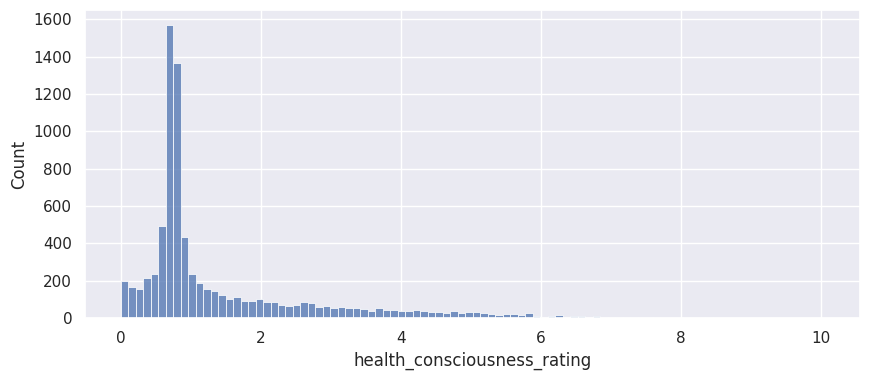

In [137]:
#variable histogram

plt.figure(figsize=(10, 4))
sns.histplot(wd_ct['health_consciousness_rating'])
plt.show()

<Axes: xlabel='health_consciousness_rating'>

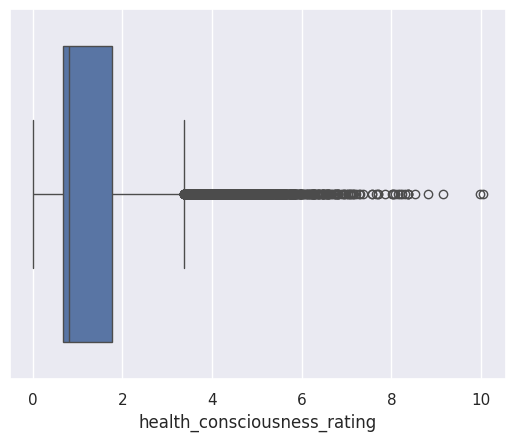

In [138]:
#variable boxplot

sns.boxplot(x=wd_ct['health_consciousness_rating'])

In [139]:
#checking for outliers

find_outliers(wd_ct['health_consciousness_rating']).shape[0]

888

###Alterations and sugestions

Another variable where we perform the log transformation to reduce skewness.

In [140]:
#add 1 and do the log transformation
wd_ct['log_health_consciousness_rating'] = np.log(wd_ct['health_consciousness_rating'] + 1)

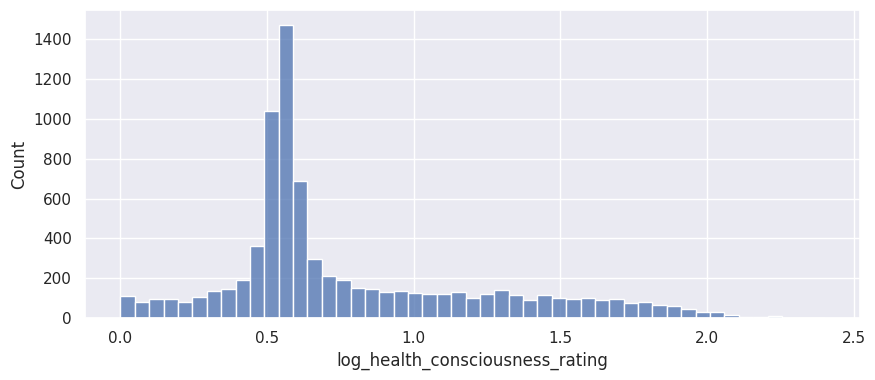

In [141]:
#transformed variable histogram

plt.figure(figsize=(10, 4))
sns.histplot(wd_ct['log_health_consciousness_rating'])
plt.show()

<Axes: xlabel='log_health_consciousness_rating'>

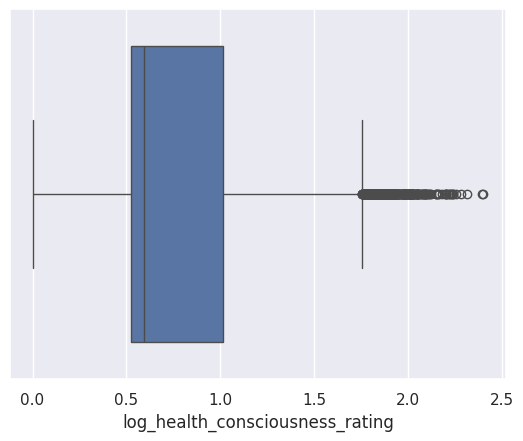

In [142]:
#transformed variable boxplot

sns.boxplot(x=wd_ct['log_health_consciousness_rating'])

In [143]:
#checking for outliers after  the transformation

find_outliers(wd_ct['log_health_consciousness_rating']).shape[0]

356

In [144]:
#drop the original
wd_ct = wd_ct.drop('health_consciousness_rating', axis=1)

Once again, the log transformation improved the distribution and reduced outliers.

##Education

(education_level)

In [145]:
#basic statistics

print(wd_ct['education_level'].describe())

count    7875.000000
mean        6.287219
std         2.920520
min         0.000000
25%         4.033600
50%         6.347100
75%         8.565050
max        14.244000
Name: education_level, dtype: float64


In [146]:
#checking for missing values

print(f'Missing values: {wd_ct["education_level"].isna().sum()}')

Missing values: 284


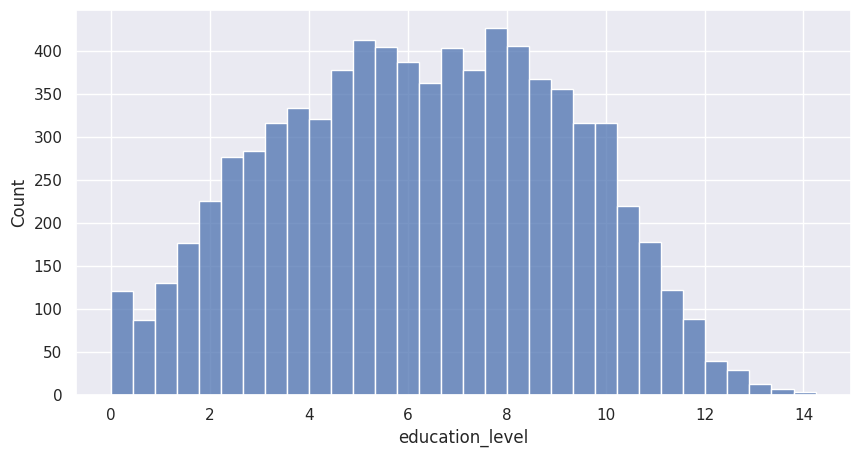

In [147]:
#variable histogram

plt.figure(figsize=(10,5))
sns.histplot(wd_ct['education_level'])
plt.show()

<Axes: ylabel='education_level'>

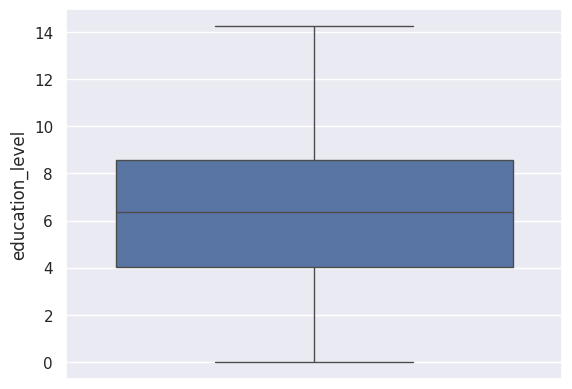

In [148]:
#variable boxplot

sns.boxplot(wd_ct['education_level'])

No transformation needed for this variable.

##Stress Management

(stress_management_score)

###Analysis and Visuals

In [149]:
#basic statistics

print(wd_ct['stress_management_score'].describe())

count    7874.000000
mean        3.318989
std         1.114931
min         0.319200
25%         2.559850
50%         3.150200
75%         3.979275
max         8.712300
Name: stress_management_score, dtype: float64


In [150]:
#checking for missing values

print(f'Missing values: {wd_ct["stress_management_score"].isna().sum()}')

Missing values: 285


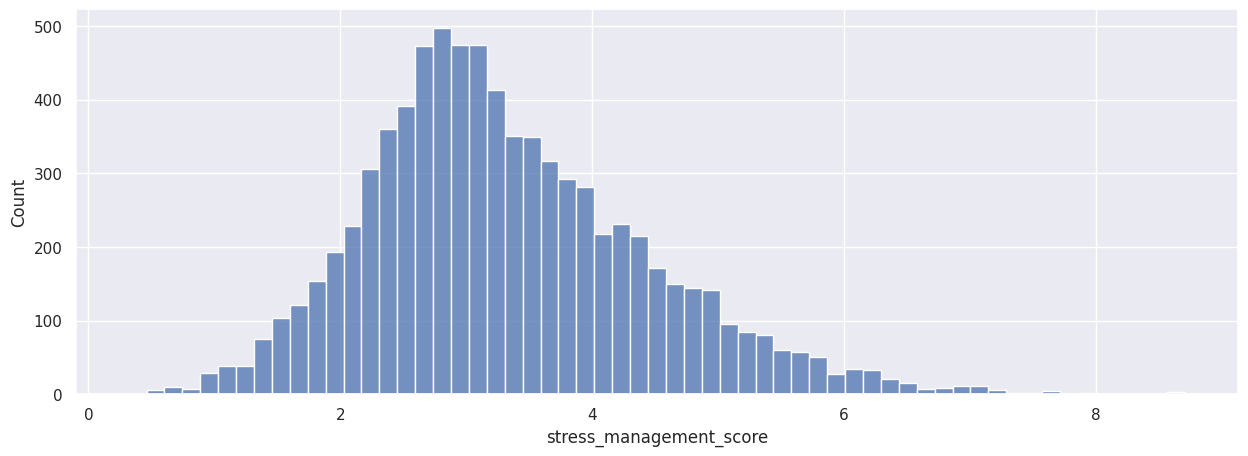

In [151]:
#variable histogram

plt.figure(figsize=(15,5))
sns.histplot(wd_ct['stress_management_score'])
plt.show()

<Axes: ylabel='stress_management_score'>

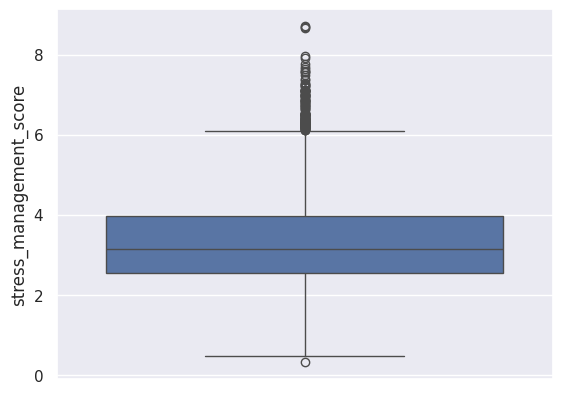

In [152]:
#variable boxplot

sns.boxplot(wd_ct['stress_management_score'])

In [153]:
#checking for outliers

find_outliers(wd_ct['stress_management_score']).shape[0]

131

In [154]:
outliers = find_outliers(wd_ct['stress_management_score'])

# Create a boolean mask: True where the value is an outlier
is_outlier = wd_ct['stress_management_score'].isin(outliers)

# Mask (replace with NaN) only the outliers
wd_ct['stress_management_score'] = wd_ct['stress_management_score'].mask(is_outlier)

Though we did have some outliers for this variable, its distribution appears to be close to normal, thus we decided to move on with it as it is.

##Eco consciousness

(eco_consciousness_score)

###Analysis and visuals

In [155]:
#basic statistics

print(wd_ct['eco_consciousness_score'].describe())

count    7954.000000
mean        0.131469
std         0.358185
min        -1.416700
25%         0.000000
50%         0.007800
75%         0.024400
max         3.247500
Name: eco_consciousness_score, dtype: float64


In [156]:
#checking for missing values

print(f'Missing values: {wd_ct["eco_consciousness_score"].isna().sum()}')

Missing values: 205


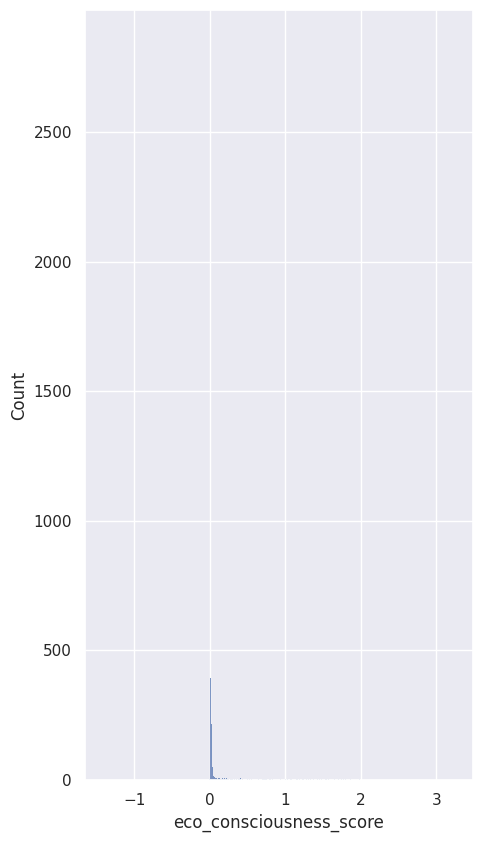

In [157]:
#variable histogram

plt.figure(figsize=(5,10))
sns.histplot(wd_ct['eco_consciousness_score'])
plt.show()

<Axes: ylabel='eco_consciousness_score'>

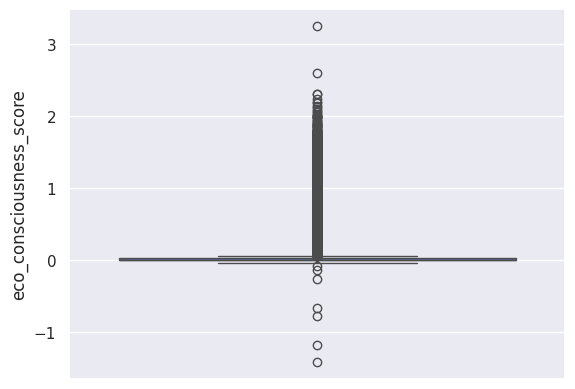

In [158]:
#variable boxplot

sns.boxplot(wd_ct['eco_consciousness_score'])

In [159]:
#checking for outliers

find_outliers(wd_ct['eco_consciousness_score']).shape[0]

1358

###Alterations and suggestions

We decided it was best to just drop this variable, since its distribution was terrible for analysis.

In [160]:
wd_ct = wd_ct.drop(columns=['eco_consciousness_score'])

##Well being

(well_being_level)

###Analysis and visuals

In [161]:
#basic statistics

print(wd_ct['well_being_level'].describe())

count    8038.000000
mean        4.765445
std         1.935673
min         1.137600
25%         3.415950
50%         4.319150
75%         5.615725
max        14.114300
Name: well_being_level, dtype: float64


In [162]:
#checking for missing values

print(f'Missing values: {wd_ct["well_being_level"].isna().sum()}')

Missing values: 121


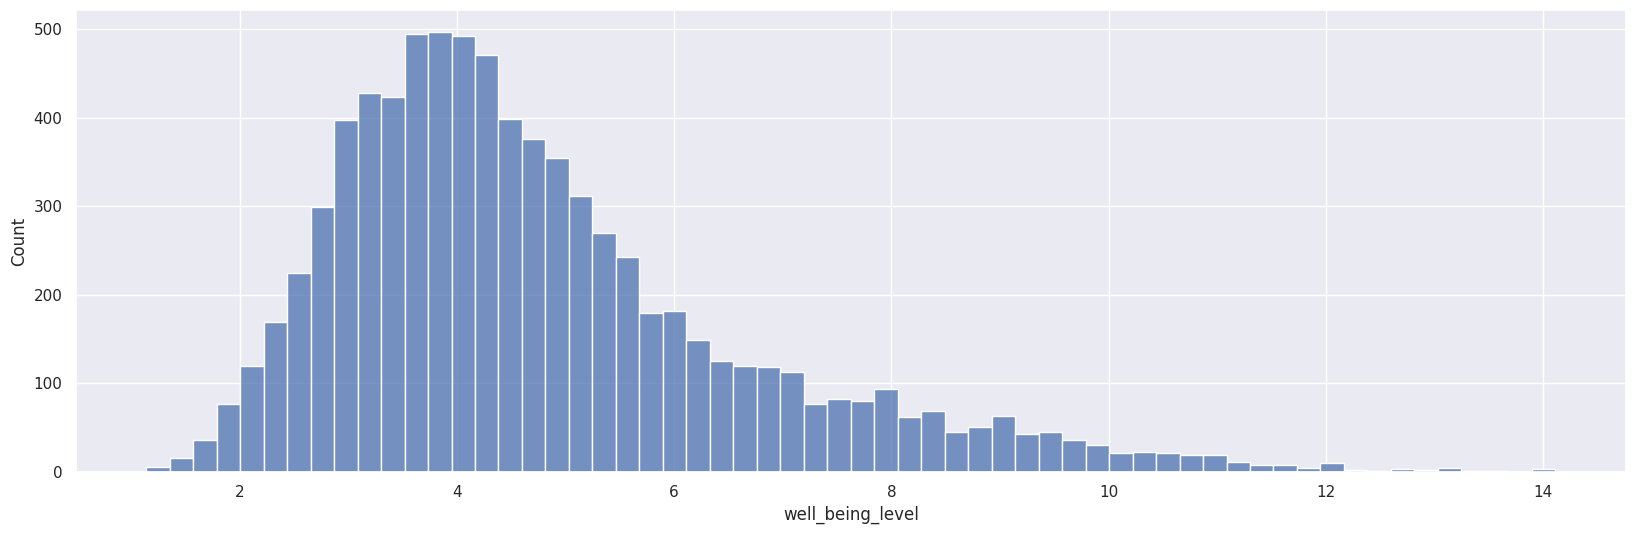

In [163]:
#variable histogram

plt.figure(figsize=(20,6))
sns.histplot(wd_ct['well_being_level'])
plt.show()

<Axes: ylabel='well_being_level'>

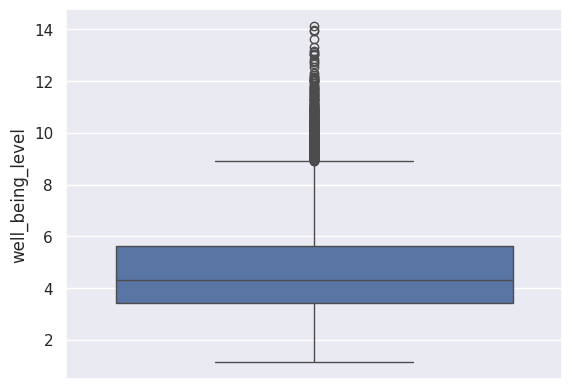

In [164]:
#variable boxplot

sns.boxplot(wd_ct['well_being_level'])

In [165]:
#checking for outliers

find_outliers(wd_ct['well_being_level']).shape[0]

382

###Alterations and suggestions

In [166]:
#perform log transformation
wd_ct['log_well_being_level'] = np.log(wd_ct['well_being_level'])

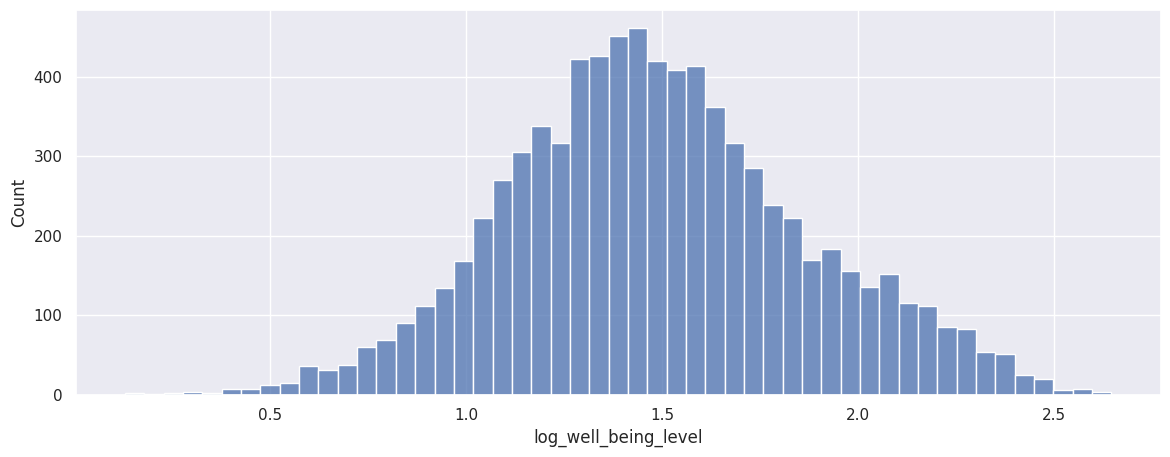

In [167]:
#variable histogram after transformation

plt.figure(figsize=(14,5))
sns.histplot(wd_ct['log_well_being_level'])
plt.show()

<Axes: ylabel='log_well_being_level'>

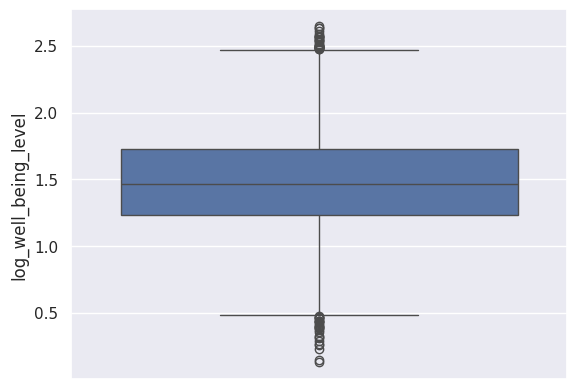

In [168]:
#variable boxplot after transformation

sns.boxplot(wd_ct['log_well_being_level'])

In [169]:
find_outliers(wd_ct['log_well_being_level']).shape[0]

56

In [170]:
#drop the old one
wd_ct = wd_ct.drop('well_being_level', axis=1)

Once again, the log transformation improved the distribution and reduced outliers.

#Imputation of missing values and scaling

After treating outliers, we started with the imputation of missing values. For that, we used the KNN algorithm, after which we proceeded to apply the MinMax scaler to normalize the data and scale it all to a [0, 1] range.

In [171]:
#Calculate number of rows removed until now
r = 100 - (wd_ct.shape[0]* 100) / (world_citizens.shape[0])
r

2.01753332532725

In [172]:
# Review the missing values
wd_ct.isnull().sum()

,0
citizen_id,0
country,40
education_level,284
financial_wellness_index,246
investments_risk_appetite,246
last_year_charity_donations,124
name,0
stress_management_score,416
gender,0
Is_male,0


In [173]:
#importing KNN imputer

from sklearn.impute import KNNImputer

#separate metric from non metric features
lst = ['citizen_id','country','is_investor','name','gender','donates','Is_male','Is_female']
wd_ct_metric = wd_ct.drop(columns=lst)

# Define and apply imputer
imputer = KNNImputer()
wd_ct[wd_ct_metric.columns] = imputer.fit_transform(wd_ct_metric)



In [174]:
##country
wd_ct['country'] = wd_ct['country'].replace(np.nan, 'unknown')

In [175]:
wd_ct.isnull().sum()

,0
citizen_id,0
country,0
education_level,0
financial_wellness_index,0
investments_risk_appetite,0
last_year_charity_donations,0
name,0
stress_management_score,0
gender,0
Is_male,0


In [176]:
#Normalize all columns of wd_ct

scaler = MinMaxScaler()
#apply scaler to metric features
lst = ['citizen_id','country','is_investor','name','gender','donates','Is_male','Is_female']
wd_ct_metric = wd_ct.drop(columns=lst)
wd_ct_scaled = wd_ct.copy()
wd_ct_scaled[wd_ct_metric.columns] = scaler.fit_transform(wd_ct_metric)


wd_ct_scaled.head(5)

,citizen_id,country,education_level,financial_wellness_index,investments_risk_appetite,last_year_charity_donations,name,stress_management_score,gender,Is_male,...,donates,log_environmental_awareness_rating,log_investment_portfolio_value,is_investor,log_investments_risk_tolerance,log_social_media_influence_score,log_avg_monthly_entertainment_expenses,log_avg_weekly_exercise_hours,log_health_consciousness_rating,log_well_being_level
0,1,Brazil,0.389315,0.576607,0.780114,0.000000,Mafalda,0.457351,Female,0,...,0,0.194221,0.387871,Common,0.917684,0.375446,0.465811,0.000000,0.259400,0.490244
1,2,New Zealand,0.345058,0.458003,0.837244,0.000000,Olive,0.242076,Female,0,...,0,0.207002,0.000000,No,0.819880,0.332630,0.504392,0.053708,0.294649,0.542269
2,3,Germany,0.662082,0.047127,0.480487,0.000000,Esther,0.615300,Female,0,...,0,0.216001,0.678226,Common,0.339357,0.701466,0.698048,0.047075,0.145913,0.533085
3,4,Germany,0.597648,0.189868,0.820323,0.020218,Ramon,0.495060,Male,1,...,1,0.209029,0.692416,Common,0.483279,0.516673,0.734570,0.018064,0.236369,0.645044
4,5,Turkey,0.427562,0.208099,0.503443,0.000000,Koray,0.325015,Male,1,...,0,0.345758,0.693531,Common,0.271762,0.646108,0.396071,0.360713,0.085719,0.316992


In [177]:
#confirming if the KNN worked

wd_ct_scaled.isnull().sum()

,0
citizen_id,0
country,0
education_level,0
financial_wellness_index,0
investments_risk_appetite,0
last_year_charity_donations,0
name,0
stress_management_score,0
gender,0
Is_male,0


Now, we see the correlation between remaining metric variables:

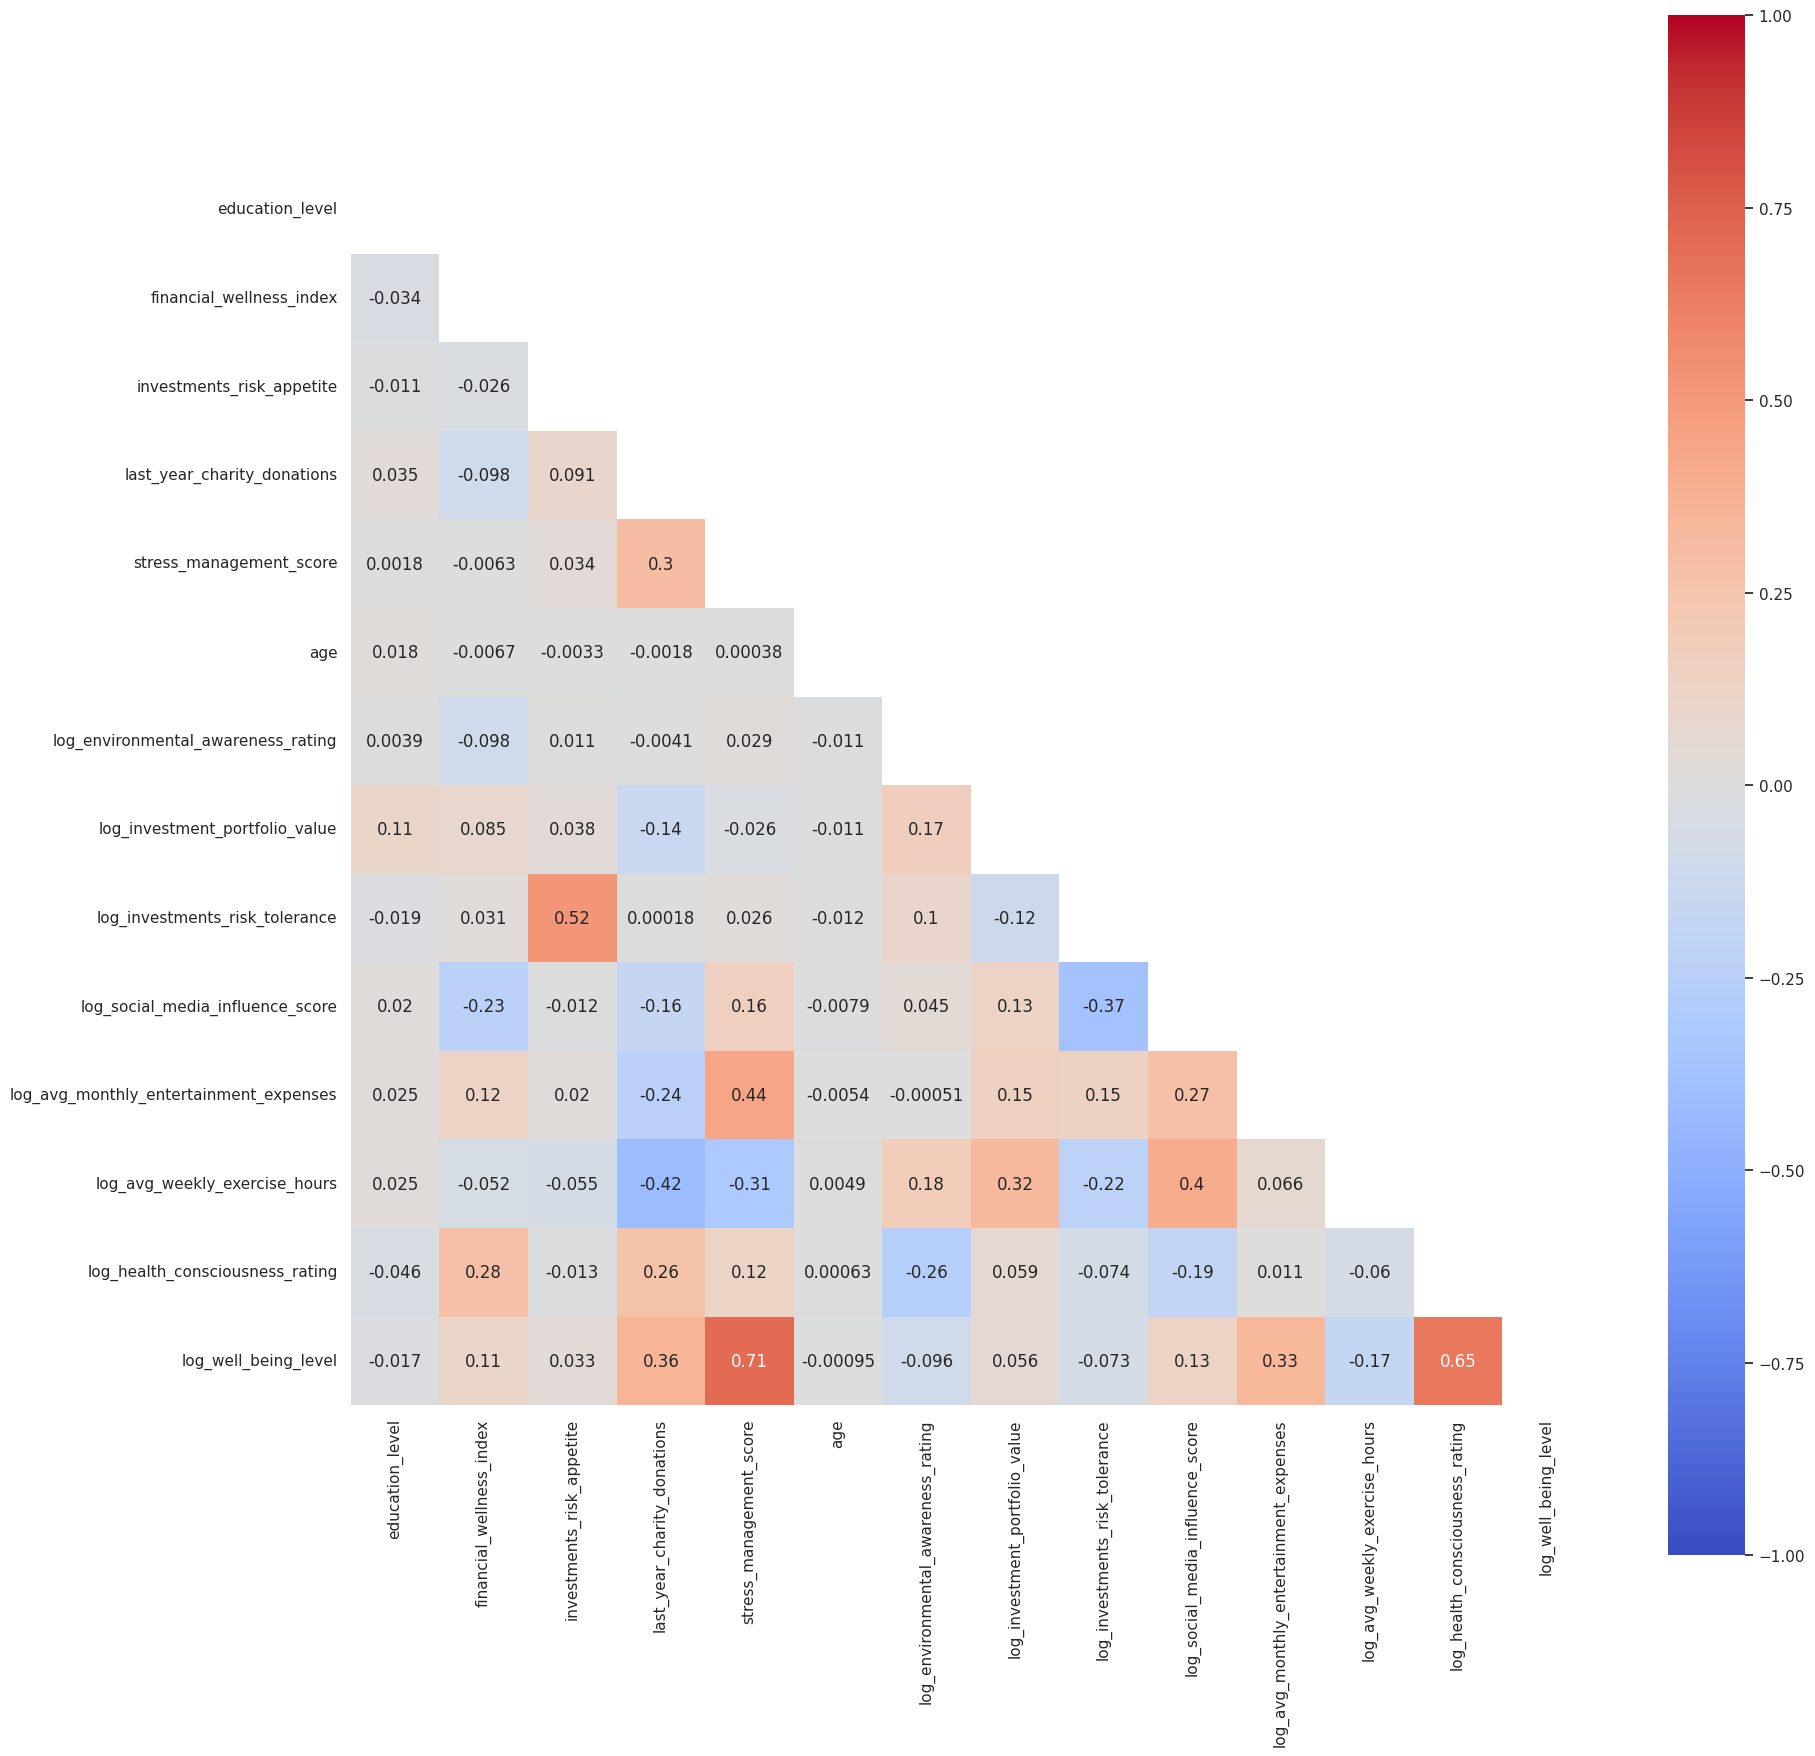

In [178]:
#see the correlation between variables using np
mask = np.zeros_like(wd_ct_scaled[wd_ct_metric.columns].corr("spearman"))
mask[np.triu_indices_from(mask)] = True
with sns.axes_style("white"):
    f, ax = plt.subplots(figsize=(20,20))
    ax = sns.heatmap(wd_ct_scaled[wd_ct_metric.columns].corr("spearman"),mask=mask, annot = True,cmap='coolwarm',square=True,vmin=-1, vmax=1)

Apart from maybe the correlations between stress_management_score and log_well_being_level (0.75) and between log_health_consciousness_rating and log_well_being_level (0.66), there seems to be no sign of multicollinearity, and we can proceed with the cluster formation.

In [179]:
wd_ct_scaled.to_excel('/content/drive/MyDrive/ML_proj/Projeto/Data/wd_ct_scaled_second.xlsx', index=False)